# Business Problem & Dataset Overview

Digital habits before bedtime can be associated with next-day fatigue.

In this project, I analyze participants' bedtime smartphone usage, screen brightness, blue-light filter usage, evening caffeine consumption, chronotype and other demographic characteristics.

The project follows a CRM-oriented behavioral analytics approach.

The main goal is to identify different participant behavior segments, understand the characteristics of each segment and develop data-driven recommendations for each group.

In the second stage, machine learning models will be used to predict next-day fatigue scores from behavioral and demographic features.

### Main Questions

- What are the main behavioral patterns in the dataset?
- How can participants be segmented according to their digital habits?
- What characterizes each behavioral segment?
- Which segments have higher observed fatigue scores?
- What type of behavioral recommendation could be associated with each segment?
- Can next-day fatigue be predicted using behavioral features?

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import os
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


import kagglehub

/kaggle/input/datasets/samartalwar/sleep-debt-and-screen-time-late-night-phone-habits/bedtime_screentime_sleep_debt.csv


In [2]:
df = pd.read_csv(
    "/kaggle/input/datasets/samartalwar/sleep-debt-and-screen-time-late-night-phone-habits/bedtime_screentime_sleep_debt.csv"
)

df.head()

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


In [3]:
df.shape


(8500, 18)

In [4]:
df.columns.tolist()

['user_id',
 'age',
 'gender',
 'occupation_type',
 'chronotype',
 'bedtime_phone_minutes',
 'primary_bedtime_app',
 'screen_brightness_pct',
 'blue_light_filter_active',
 'caffeine_post_5pm_mg',
 'physical_activity_min',
 'sleep_latency_min',
 'total_sleep_hours',
 'deep_sleep_pct',
 'rem_sleep_pct',
 'morning_alarm_snoozes',
 'next_day_fatigue_score',
 'sleep_debt_category']

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,8500.0,34.355647,11.584259,18.0,25.00,32.00,42.00,65.0
bedtime_phone_minutes,8500.0,59.250000,36.931991,1.0,31.00,51.00,79.00,180.0
screen_brightness_pct,8500.0,55.153882,19.850550,10.0,42.00,55.00,69.00,100.0
blue_light_filter_active,8500.0,0.467765,0.498989,0.0,0.00,0.00,1.00,1.0
caffeine_post_5pm_mg,8500.0,33.222471,51.935645,0.0,0.00,0.00,55.00,250.0
physical_activity_min,8500.0,35.701412,20.819390,0.0,21.00,35.00,50.00,112.0
sleep_latency_min,8500.0,40.671471,17.444914,6.0,28.20,37.60,49.70,123.3
total_sleep_hours,8500.0,6.266209,1.446258,3.2,5.24,6.33,7.35,9.8
deep_sleep_pct,8500.0,21.735741,3.069377,8.1,19.70,21.90,23.90,28.0
rem_sleep_pct,8500.0,19.105859,2.546459,9.6,17.40,19.10,20.80,27.0


# Exploratory Data Analysis (EDA)

**Numerical Variables Overview**

The numerical variables show considerable variation across participants. The average bedtime phone usage is around 59 minutes, while screen brightness averages approximately 55%. Evening caffeine consumption is relatively low for most participants, with a median of 0 mg, although some participants report substantially higher intake. Physical activity averages around 36 minutes per day.

For sleep-related variables, participants sleep an average of approximately 6.27 hours, with an average sleep latency of about 41 minutes. Deep sleep and REM sleep account for approximately 21.7% and 19.1% of total sleep, respectively. The average number of morning alarm snoozes is around 2.8.

The target variable, next_day_fatigue_score, has a mean of 3.79 and ranges from 1 to 10. Overall, the variables show different levels of variation and several features contain relatively high maximum values compared with their median values. These distributions will be examined further before deciding whether any outlier treatment is necessary.

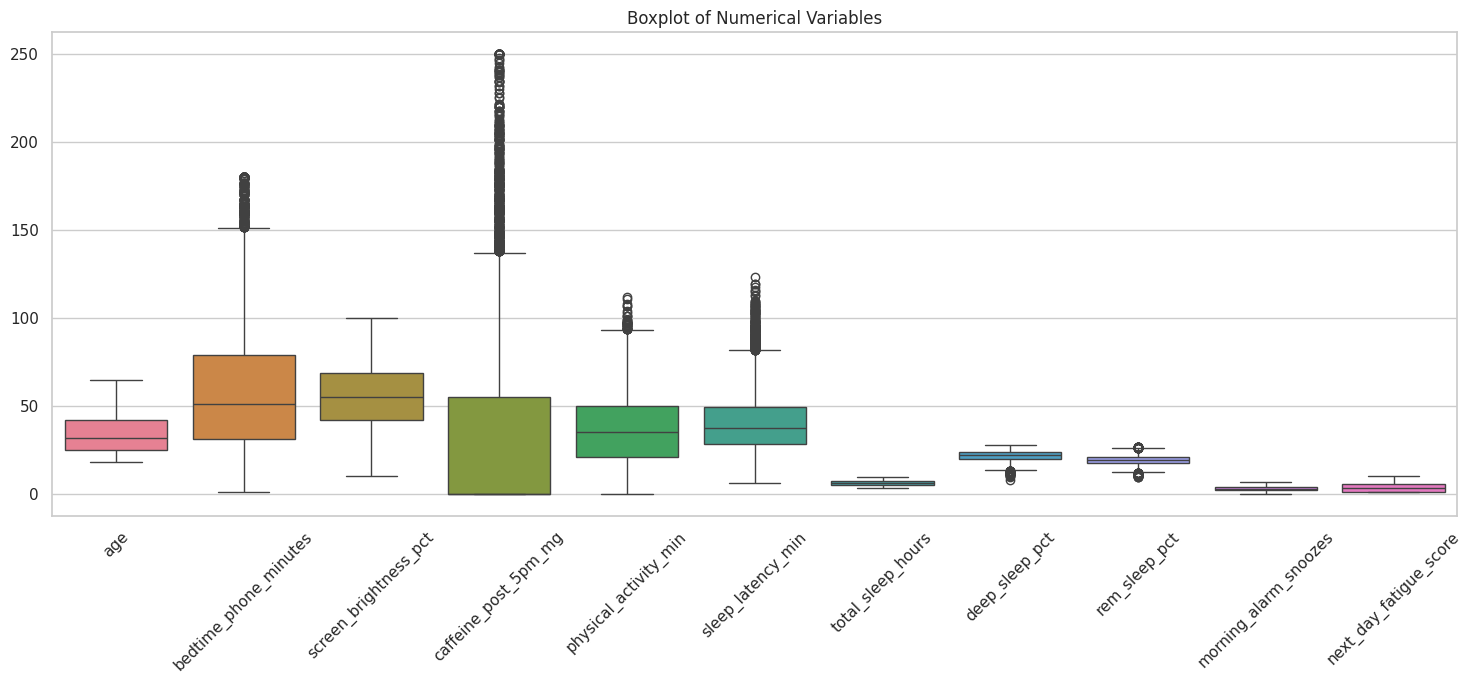

In [7]:
numeric_columns = [
    "age",
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "caffeine_post_5pm_mg",
    "physical_activity_min",
    "sleep_latency_min",
    "total_sleep_hours",
    "deep_sleep_pct",
    "rem_sleep_pct",
    "morning_alarm_snoozes",
    "next_day_fatigue_score"
]

plt.figure(figsize=(15, 7))

sns.boxplot(data=df[numeric_columns])

plt.xticks(rotation=45)
plt.title("Boxplot of Numerical Variables")
plt.tight_layout()
plt.show()

In [8]:
missing_df = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
})

missing_df.sort_values(
    "missing_percentage",
    ascending=False
)

,missing_count,missing_percentage
user_id,0,0.0
age,0,0.0
gender,0,0.0
occupation_type,0,0.0
chronotype,0,0.0
bedtime_phone_minutes,0,0.0
primary_bedtime_app,0,0.0
screen_brightness_pct,0,0.0
blue_light_filter_active,0,0.0
caffeine_post_5pm_mg,0,0.0


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
unique_df = pd.DataFrame({
    "column": df.columns,
    "unique_count": df.nunique()
})

unique_df

,column,unique_count
user_id,user_id,8500
age,age,48
gender,gender,3
occupation_type,occupation_type,5
chronotype,chronotype,3
bedtime_phone_minutes,bedtime_phone_minutes,179
primary_bedtime_app,primary_bedtime_app,6
screen_brightness_pct,screen_brightness_pct,91
blue_light_filter_active,blue_light_filter_active,2
caffeine_post_5pm_mg,caffeine_post_5pm_mg,218


In [11]:
df["next_day_fatigue_score"].describe()

count    8500.000000
mean        3.794671
std         2.685153
min         1.000000
25%         1.100000
50%         3.200000
75%         5.600000
max        10.000000
Name: next_day_fatigue_score, dtype: float64

In [12]:
categorical_columns = [
    "gender",
    "occupation_type",
    "chronotype",
    "primary_bedtime_app",
    "sleep_debt_category"
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts())


--- gender ---
gender
Female        4347
Male          3905
Non-Binary     248
Name: count, dtype: int64

--- occupation_type ---
occupation_type
Corporate 9-to-5             2838
Remote Tech                  2142
Student                      1622
Healthcare / Shift Worker     997
Freelance / Creative          901
Name: count, dtype: int64

--- chronotype ---
chronotype
Intermediate    3880
Night Owl       2455
Morning Lark    2165
Name: count, dtype: int64

--- primary_bedtime_app ---
primary_bedtime_app
TikTok / Reels              2198
YouTube                     1928
Instagram / Reddit          1630
Streaming (Netflix/Hulu)    1301
Messaging / Chat             847
News / Reading               596
Name: count, dtype: int64

--- sleep_debt_category ---
sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64


The categorical variables provide an initial overview of the participants’ demographic, lifestyle, and bedtime behavior profiles. The dataset is relatively balanced between Female and Male participants, while Non-Binary participants represent a smaller group. Corporate 9-to-5 and Remote Tech are the most common occupation types, and Intermediate is the most frequent chronotype. For bedtime app usage, TikTok / Reels and YouTube are the most common choices. In terms of sleep debt, Moderate Debt is clearly the most common category, followed by Mild Deficit and Optimal Recovery, while Severe Sleep Debt represents the smallest group.

These distributions will be used as a starting point for exploring behavioral patterns and their relationship with sleep outcomes and next-day fatigue.

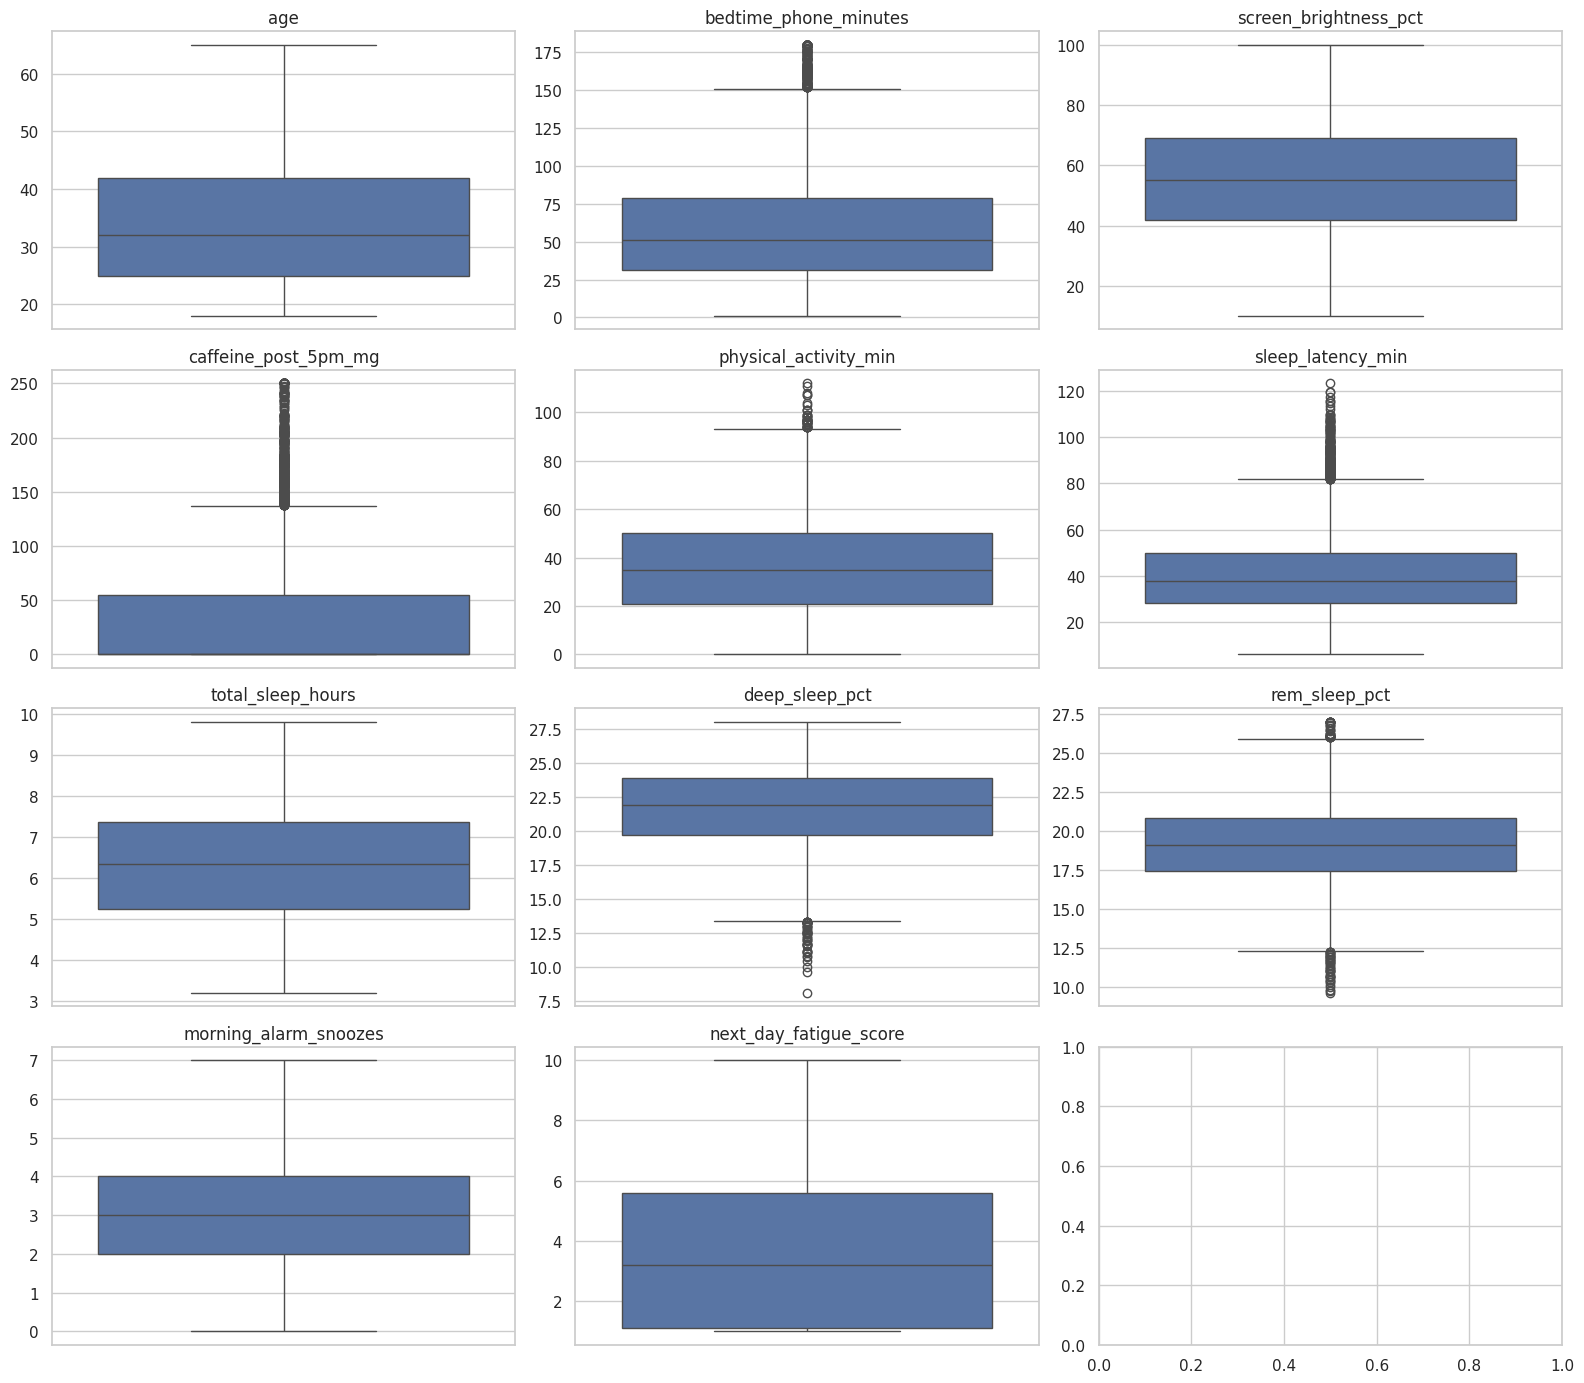

In [13]:
fig, axes = plt.subplots(4, 3, figsize=(16, 14))

for ax, column in zip(axes.flat, numeric_columns):
    sns.boxplot(y=df[column], ax=ax)
    ax.set_title(column)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [14]:
outlier_summary = []

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()
    
    outlier_percentage = outlier_count / len(df) * 100
    
    outlier_summary.append({
        "column": column,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage": outlier_percentage
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    "outlier_percentage",
    ascending=False
).round(2)

,column,lower_bound,upper_bound,outlier_count,outlier_percentage
3,caffeine_post_5pm_mg,-82.50,137.50,483,5.68
5,sleep_latency_min,-4.05,81.95,247,2.91
1,bedtime_phone_minutes,-41.00,151.00,237,2.79
8,rem_sleep_pct,12.30,25.90,76,0.89
7,deep_sleep_pct,13.40,30.20,50,0.59
4,physical_activity_min,-22.50,93.50,40,0.47
0,age,-0.50,67.50,0,0.00
2,screen_brightness_pct,1.50,109.50,0,0.00
6,total_sleep_hours,2.08,10.51,0,0.00
9,morning_alarm_snoozes,-1.00,7.00,0,0.00


**Outlier Analysis**

Outliers were examined using boxplots and the IQR method. The highest proportion of outliers was observed in evening caffeine consumption, followed by sleep latency and bedtime phone usage.

These observations were not automatically treated as errors because extreme values can represent valid differences in individual behavior. Since the values remain within plausible ranges, no observations were removed at this stage.

The original data will be preserved for further behavioral analysis and modeling.

In [15]:
participant_360 = df.copy()

participant_360.head()

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


In [16]:
df[["age", "gender", "occupation_type", "chronotype"]].describe(include="all")

,age,gender,occupation_type,chronotype
count,8500.000000,8500,8500,8500
unique,NaN,3,5,3
top,NaN,Female,Corporate 9-to-5,Intermediate
freq,NaN,4347,2838,3880
mean,34.355647,NaN,NaN,NaN
std,11.584259,NaN,NaN,NaN
min,18.000000,NaN,NaN,NaN
25%,25.000000,NaN,NaN,NaN
50%,32.000000,NaN,NaN,NaN
75%,42.000000,NaN,NaN,NaN


In [17]:
occupation_counts = (
    df["occupation_type"]
    .value_counts()
    .rename_axis("occupation_type")
    .reset_index(name="participant_count")
)

occupation_counts["percentage"] = (
    occupation_counts["participant_count"] / len(df) * 100
).round(2)

occupation_counts


,occupation_type,participant_count,percentage
0,Corporate 9-to-5,2838,33.39
1,Remote Tech,2142,25.20
2,Student,1622,19.08
3,Healthcare / Shift Worker,997,11.73
4,Freelance / Creative,901,10.60


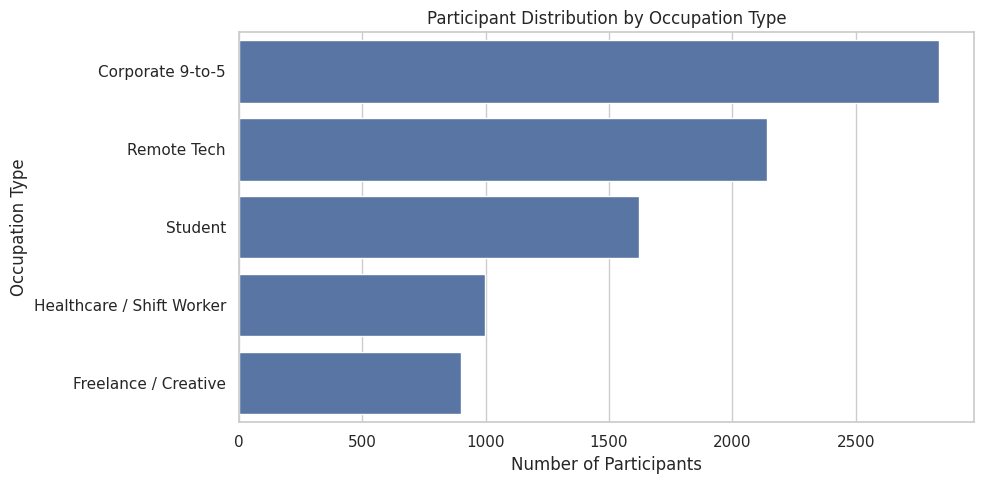

In [18]:
occupation_counts = df["occupation_type"].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=occupation_counts.values,
    y=occupation_counts.index
)

plt.title("Participant Distribution by Occupation Type")
plt.xlabel("Number of Participants")
plt.ylabel("Occupation Type")
plt.tight_layout()
plt.show()

In [19]:
gender_counts = (
    df["gender"]
    .value_counts()
    .rename_axis("gender")
    .reset_index(name="participant_count")
)

gender_counts["percentage"] = (
    gender_counts["participant_count"] / len(df) * 100
).round(2)

gender_counts

,gender,participant_count,percentage
0,Female,4347,51.14
1,Male,3905,45.94
2,Non-Binary,248,2.92


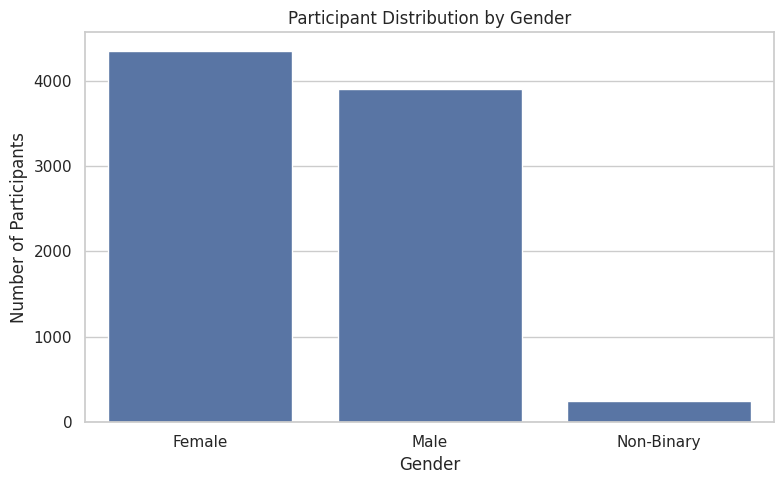

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_counts,
    x="gender",
    y="participant_count"
)

plt.title("Participant Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Participants")
plt.tight_layout()
plt.show()

The dataset has a relatively balanced gender distribution. Female participants represent 51.14% of the dataset, while Male participants account for 45.94%. Non-Binary participants represent 2.92% of the total sample.

This distribution provides representation across different gender groups and allows gender-based behavioral patterns to be explored in the following analyses.

In [21]:
chronotype_counts = (
    df["chronotype"]
    .value_counts()
    .rename_axis("chronotype")
    .reset_index(name="participant_count")
)

chronotype_counts["percentage"] = (
    chronotype_counts["participant_count"] / len(df) * 100
).round(2)

chronotype_counts

,chronotype,participant_count,percentage
0,Intermediate,3880,45.65
1,Night Owl,2455,28.88
2,Morning Lark,2165,25.47


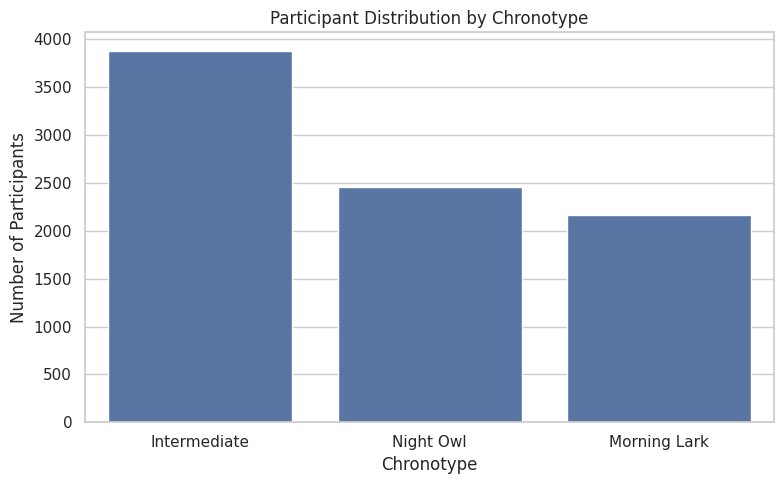

In [22]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=chronotype_counts,
    x="chronotype",
    y="participant_count"
)

plt.title("Participant Distribution by Chronotype")
plt.xlabel("Chronotype")
plt.ylabel("Number of Participants")
plt.tight_layout()
plt.show()

Intermediate participants represent the largest chronotype group, accounting for 45.65% of the dataset. Night Owls represent 28.88%, while Morning Larks account for 25.47%.

The distribution includes all three chronotype groups with a noticeable concentration in the Intermediate category. This variable will be useful for examining differences in bedtime phone usage, sleep-related behaviors, and next-day fatigue across chronotype profiles.

In [23]:
app_counts = (
    df["primary_bedtime_app"]
    .value_counts()
    .rename_axis("primary_bedtime_app")
    .reset_index(name="participant_count")
)

app_counts["percentage"] = (
    app_counts["participant_count"] / len(df) * 100
).round(2)

app_counts

,primary_bedtime_app,participant_count,percentage
0,TikTok / Reels,2198,25.86
1,YouTube,1928,22.68
2,Instagram / Reddit,1630,19.18
3,Streaming (Netflix/Hulu),1301,15.31
4,Messaging / Chat,847,9.96
5,News / Reading,596,7.01


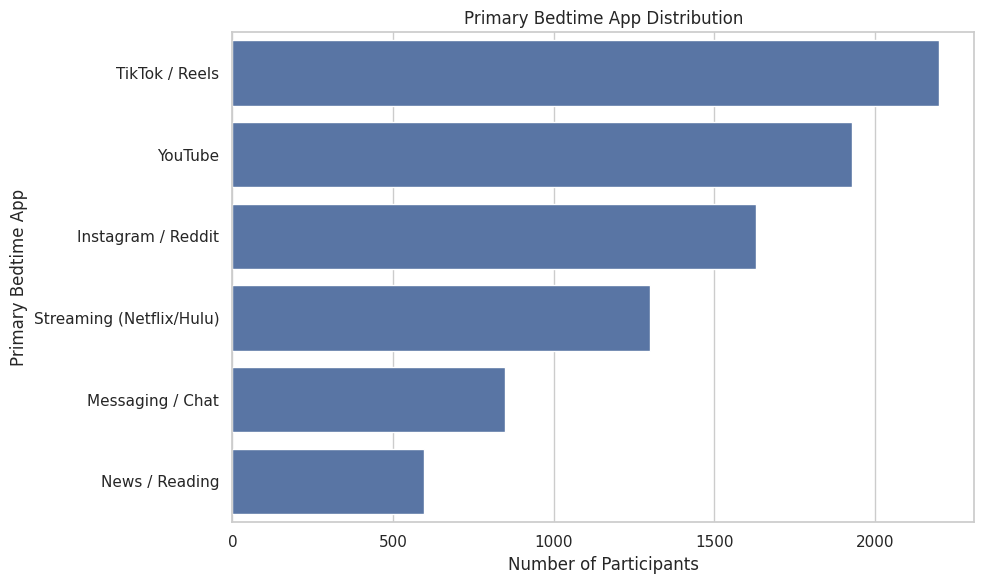

In [24]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=app_counts,
    x="participant_count",
    y="primary_bedtime_app"
)

plt.title("Primary Bedtime App Distribution")
plt.xlabel("Number of Participants")
plt.ylabel("Primary Bedtime App")

plt.tight_layout()
plt.show()

TikTok / Reels is the most common primary bedtime app, representing 25.86% of participants, followed by YouTube with 22.68%. Instagram / Reddit accounts for 19.18%, while Streaming platforms represent 15.31%.

Messaging / Chat and News / Reading are less common, accounting for 9.96% and 7.01% of participants, respectively. Overall, short-form video, video streaming, and social media platforms represent a substantial share of bedtime app usage in the dataset.

In [25]:
bedtime_phone_summary = df["bedtime_phone_minutes"].describe().round(2)

bedtime_phone_summary

count    8500.00
mean       59.25
std        36.93
min         1.00
25%        31.00
50%        51.00
75%        79.00
max       180.00
Name: bedtime_phone_minutes, dtype: float64

In [26]:
bedtime_phone_stats = pd.DataFrame({
    "metric": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Standard Deviation"
    ],
    "value": [
        df["bedtime_phone_minutes"].mean(),
        df["bedtime_phone_minutes"].median(),
        df["bedtime_phone_minutes"].min(),
        df["bedtime_phone_minutes"].max(),
        df["bedtime_phone_minutes"].std()
    ]
})

bedtime_phone_stats["value"] = bedtime_phone_stats["value"].round(2)

bedtime_phone_stats

,metric,value
0,Mean,59.25
1,Median,51.00
2,Minimum,1.00
3,Maximum,180.00
4,Standard Deviation,36.93


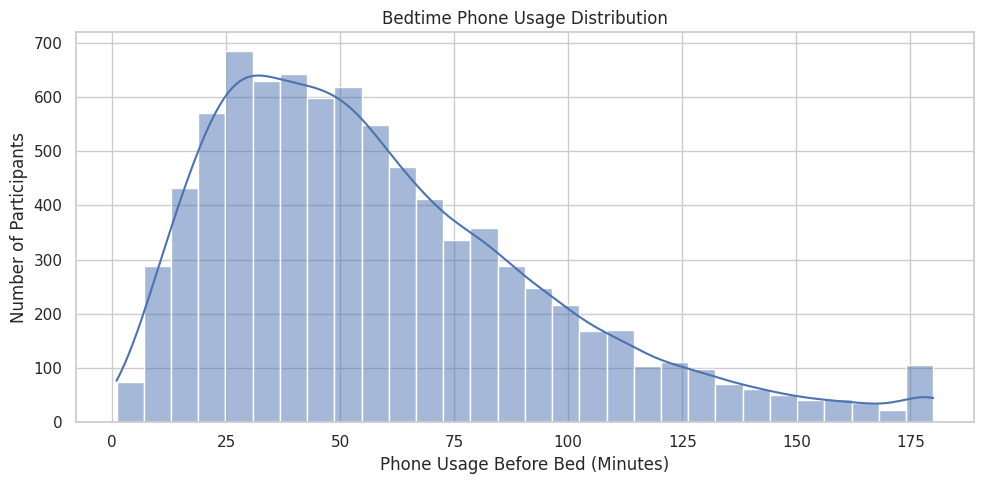

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="bedtime_phone_minutes",
    bins=30,
    kde=True
)

plt.title("Bedtime Phone Usage Distribution")
plt.xlabel("Phone Usage Before Bed (Minutes)")
plt.ylabel("Number of Participants")

plt.tight_layout()
plt.show()

Participants spend an average of 59.25 minutes on their phones before bedtime, with a median usage of 51 minutes. The values range from 1 to 180 minutes, showing considerable variation in bedtime phone usage.

The mean being higher than the median suggests that some participants have relatively high bedtime phone usage. This variation will be useful for examining behavioral patterns and its association with sleep-related outcomes and next-day fatigue.

In [28]:
brightness_stats = pd.DataFrame({
    "metric": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Standard Deviation"
    ],
    "value": [
        df["screen_brightness_pct"].mean(),
        df["screen_brightness_pct"].median(),
        df["screen_brightness_pct"].min(),
        df["screen_brightness_pct"].max(),
        df["screen_brightness_pct"].std()
    ]
})

brightness_stats["value"] = brightness_stats["value"].round(2)

brightness_stats

,metric,value
0,Mean,55.15
1,Median,55.00
2,Minimum,10.00
3,Maximum,100.00
4,Standard Deviation,19.85


The average screen brightness is 55.15%, with a median of 55%. Brightness levels range from 10% to 100%, indicating substantial variation in participants' bedtime screen settings.

The mean and median are nearly identical, suggesting a relatively balanced distribution around the center. This variable will be further examined together with blue-light filter usage and other bedtime behaviors.

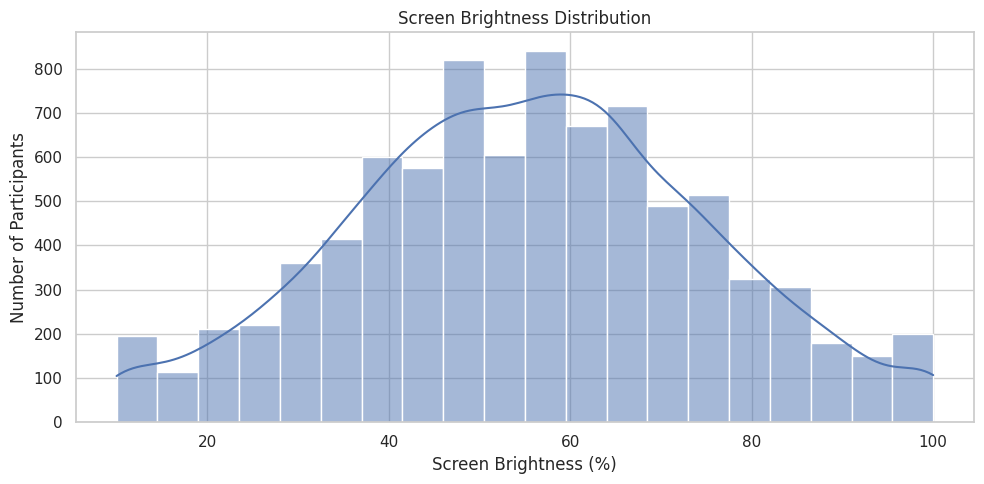

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="screen_brightness_pct",
    bins=20,
    kde=True
)

plt.title("Screen Brightness Distribution")
plt.xlabel("Screen Brightness (%)")
plt.ylabel("Number of Participants")

plt.tight_layout()
plt.show()

In [30]:
blue_light_counts = (
    df["blue_light_filter_active"]
    .value_counts()
    .rename_axis("blue_light_filter_active")
    .reset_index(name="participant_count")
)

blue_light_counts["percentage"] = (
    blue_light_counts["participant_count"] / len(df) * 100
).round(2)

blue_light_counts

,blue_light_filter_active,participant_count,percentage
0,0,4524,53.22
1,1,3976,46.78


The blue-light filter is inactive for 53.22% of participants, while 46.78% of participants have it active.

The distribution is relatively balanced, although slightly more participants do not use the blue-light filter. This variable will be considered as part of the participants' bedtime screen-use behavior.

In [31]:
blue_light_counts["filter_status"] = blue_light_counts[
    "blue_light_filter_active"
].map({
    0: "Inactive",
    1: "Active"
})

blue_light_counts

,blue_light_filter_active,participant_count,percentage,filter_status
0,0,4524,53.22,Inactive
1,1,3976,46.78,Active


Among the participants, 53.22% do not use the blue-light filter, while 46.78% have the filter active.

The two groups are relatively balanced, with a slightly higher share of participants not using the filter. This provides a useful overview of blue-light filter usage within the participants' bedtime screen habits.

In [32]:
caffeine_stats = pd.DataFrame({
    "metric": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Standard Deviation"
    ],
    "value": [
        df["caffeine_post_5pm_mg"].mean(),
        df["caffeine_post_5pm_mg"].median(),
        df["caffeine_post_5pm_mg"].min(),
        df["caffeine_post_5pm_mg"].max(),
        df["caffeine_post_5pm_mg"].std()
    ]
})

caffeine_stats["value"] = caffeine_stats["value"].round(2)

caffeine_stats

,metric,value
0,Mean,33.22
1,Median,0.00
2,Minimum,0.00
3,Maximum,250.00
4,Standard Deviation,51.94


The average caffeine consumption after 5 PM is 33.22 mg, while the median is 0 mg. This indicates that at least half of the participants do not consume caffeine after 5 PM.

Caffeine consumption ranges from 0 to 250 mg, with a standard deviation of 51.94 mg. The difference between the mean and median suggests that caffeine consumption is concentrated among a smaller group of participants with higher intake levels.

In [33]:
caffeine_groups = pd.cut(
    df["caffeine_post_5pm_mg"],
    bins=[-1, 0, 50, 100, 150, 200, 250],
    labels=[
        "0 mg",
        "1–50 mg",
        "51–100 mg",
        "101–150 mg",
        "151–200 mg",
        "201–250 mg"
    ]
)

caffeine_distribution = (
    caffeine_groups
    .value_counts()
    .sort_index()
    .reset_index()
)

caffeine_distribution.columns = ["caffeine_range", "participant_count"]

caffeine_distribution["percentage"] = (
    caffeine_distribution["participant_count"] / len(df) * 100
).round(2)

caffeine_distribution

,caffeine_range,participant_count,percentage
0,0 mg,4950,58.24
1,1–50 mg,1278,15.04
2,51–100 mg,1267,14.91
3,101–150 mg,635,7.47
4,151–200 mg,234,2.75
5,201–250 mg,136,1.60


A total of 58.24% of participants report no caffeine consumption after 5 PM. Among the participants who consume caffeine, 15.04% consume 1–50 mg and 14.91% consume 51–100 mg.

Higher caffeine intake levels are less common, with 7.47% consuming 101–150 mg, 2.75% consuming 151–200 mg, and 1.60% consuming 201–250 mg.

Overall, evening caffeine consumption is concentrated in the lower ranges, while a smaller proportion of participants report higher intake levels.

In [34]:
physical_activity_stats = pd.DataFrame({
    "metric": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Standard Deviation"
    ],
    "value": [
        df["physical_activity_min"].mean(),
        df["physical_activity_min"].median(),
        df["physical_activity_min"].min(),
        df["physical_activity_min"].max(),
        df["physical_activity_min"].std()
    ]
})

physical_activity_stats["value"] = physical_activity_stats["value"].round(2)

physical_activity_stats

,metric,value
0,Mean,35.70
1,Median,35.00
2,Minimum,0.00
3,Maximum,112.00
4,Standard Deviation,20.82


Participants report an average of 35.70 minutes of physical activity, with a median of 35 minutes per day. Physical activity ranges from 0 to 112 minutes, with a standard deviation of 20.82 minutes.

The mean and median are very close, suggesting that the distribution is relatively centered around 35 minutes. However, the wide range shows noticeable differences in physical activity levels across participants.

In [35]:
physical_activity_groups = pd.cut(
    df["physical_activity_min"],
    bins=[-1, 15, 30, 60, 90, 120],
    labels=[
        "0–15 min",
        "16–30 min",
        "31–60 min",
        "61–90 min",
        "91–120 min"
    ]
)

physical_activity_distribution = (
    physical_activity_groups
    .value_counts()
    .sort_index()
    .reset_index()
)

physical_activity_distribution.columns = [
    "physical_activity_range",
    "participant_count"
]

physical_activity_distribution["percentage"] = (
    physical_activity_distribution["participant_count"] / len(df) * 100
).round(2)

physical_activity_distribution

,physical_activity_range,participant_count,percentage
0,0–15 min,1539,18.11
1,16–30 min,1982,23.32
2,31–60 min,3942,46.38
3,61–90 min,985,11.59
4,91–120 min,52,0.61


The largest group of participants, representing 46.38% of the dataset, reports between 31 and 60 minutes of physical activity.

Participants with 16–30 minutes of activity account for 23.32%, while 18.11% report 0–15 minutes. Higher activity levels are less common, with 11.59% reporting 61–90 minutes and only 0.61% reporting 91–120 minutes.

Overall, physical activity is mainly concentrated between 16 and 60 minutes, with 31–60 minutes being the most common range.

In [36]:
sleep_latency_stats = pd.DataFrame({
    "metric": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Standard Deviation"
    ],
    "value": [
        df["sleep_latency_min"].mean(),
        df["sleep_latency_min"].median(),
        df["sleep_latency_min"].min(),
        df["sleep_latency_min"].max(),
        df["sleep_latency_min"].std()
    ]
})

sleep_latency_stats["value"] = sleep_latency_stats["value"].round(2)

sleep_latency_stats

,metric,value
0,Mean,40.67
1,Median,37.60
2,Minimum,6.00
3,Maximum,123.30
4,Standard Deviation,17.44


Participants have an average sleep latency of 40.67 minutes, while the median is 37.60 minutes. Sleep latency ranges from 6 to 123.30 minutes, with a standard deviation of 17.44 minutes.

The mean is slightly higher than the median, suggesting that some participants have relatively longer sleep latency values. Overall, the results show noticeable variation in the time participants need to fall asleep.

In [37]:
sleep_latency_groups = pd.cut(
    df["sleep_latency_min"],
    bins=[0, 15, 30, 45, 60, 90, 130],
    labels=[
        "0–15 min",
        "16–30 min",
        "31–45 min",
        "46–60 min",
        "61–90 min",
        "91–130 min"
    ]
)

sleep_latency_distribution = (
    sleep_latency_groups
    .value_counts()
    .sort_index()
    .reset_index()
)

sleep_latency_distribution.columns = [
    "sleep_latency_range",
    "participant_count"
]

sleep_latency_distribution["percentage"] = (
    sleep_latency_distribution["participant_count"] / len(df) * 100
).round(2)

sleep_latency_distribution

,sleep_latency_range,participant_count,percentage
0,0–15 min,202,2.38
1,16–30 min,2356,27.72
2,31–45 min,3122,36.73
3,46–60 min,1666,19.60
4,61–90 min,1037,12.20
5,91–130 min,117,1.38


The largest group of participants, representing 36.73% of the dataset, has a sleep latency of 31–45 minutes. This is followed by 27.72% of participants with a latency of 16–30 minutes and 19.60% with a latency of 46–60 minutes.

A smaller proportion of participants report longer sleep latency, with 12.20% falling within the 61–90 minute range and 1.38% within the 91–130 minute range. Only 2.38% of participants fall within the 0–15 minute range.

Overall, sleep latency is mainly concentrated between 16 and 60 minutes.

In [38]:
sleep_hours_stats = pd.DataFrame({
    "metric": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Standard Deviation"
    ],
    "value": [
        df["total_sleep_hours"].mean(),
        df["total_sleep_hours"].median(),
        df["total_sleep_hours"].min(),
        df["total_sleep_hours"].max(),
        df["total_sleep_hours"].std()
    ]
})

sleep_hours_stats["value"] = sleep_hours_stats["value"].round(2)

sleep_hours_stats

,metric,value
0,Mean,6.27
1,Median,6.33
2,Minimum,3.20
3,Maximum,9.80
4,Standard Deviation,1.45


Participants have an average total sleep duration of **6.27 hours**, while the median is **6.33 hours**. Sleep duration ranges from **3.20 to 9.80 hours**, with a standard deviation of **1.45 hours**.

The mean and median are very close, suggesting that the distribution is relatively balanced around the center. However, the wide range shows noticeable differences in total sleep duration across participants.

This variable will be further explored through its distribution and its relationship with other sleep-related behaviors.

In [39]:
sleep_hours_groups = pd.cut(
    df["total_sleep_hours"],
    bins=[0, 4, 5, 6, 7, 8, 10],
    labels=[
        "0–4 hours",
        "4–5 hours",
        "5–6 hours",
        "6–7 hours",
        "7–8 hours",
        "8–10 hours"
    ],
    include_lowest=True
)

sleep_hours_distribution = (
    sleep_hours_groups
    .value_counts()
    .sort_index()
    .reset_index()
)

sleep_hours_distribution.columns = [
    "sleep_duration_range",
    "participant_count"
]

sleep_hours_distribution["percentage"] = (
    sleep_hours_distribution["participant_count"] / len(df) * 100
).round(2)

sleep_hours_distribution

,sleep_duration_range,participant_count,percentage
0,0–4 hours,649,7.64
1,4–5 hours,1086,12.78
2,5–6 hours,1820,21.41
3,6–7 hours,2096,24.66
4,7–8 hours,1880,22.12
5,8–10 hours,969,11.40


The largest group of participants, representing 24.66% of the dataset, sleeps between 6 and 7 hours per night. This is followed by 22.12% of participants who sleep between 7 and 8 hours and 21.41% who sleep between 5 and 6 hours.

Participants sleeping between 4 and 5 hours account for 12.78%, while 11.40% sleep between 8 and 10 hours. The smallest group, representing 7.64% of participants, sleeps between 0 and 4 hours.

Overall, most participants have a total sleep duration between 5 and 8 hours.

In [40]:
deep_sleep_stats = pd.DataFrame({
    "metric": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Standard Deviation"
    ],
    "value": [
        df["deep_sleep_pct"].mean(),
        df["deep_sleep_pct"].median(),
        df["deep_sleep_pct"].min(),
        df["deep_sleep_pct"].max(),
        df["deep_sleep_pct"].std()
    ]
})

deep_sleep_stats["value"] = deep_sleep_stats["value"].round(2)

deep_sleep_stats

,metric,value
0,Mean,21.74
1,Median,21.90
2,Minimum,8.10
3,Maximum,28.00
4,Standard Deviation,3.07


Participants have an average deep sleep percentage of **21.74%**, while the median is **21.90%**. The values range from **8.10% to 28.00%**, with a standard deviation of **3.07 percentage points**.

The mean and median are very close, suggesting that the distribution is relatively balanced around the center. Overall, most participants have deep sleep percentages close to the average, although some variation can be observed across participants.

In [41]:
deep_sleep_groups = pd.cut(
    df["deep_sleep_pct"],
    bins=[0, 15, 20, 25, 30],
    labels=[
        "0–15%",
        "15–20%",
        "20–25%",
        "25–30%"
    ],
    include_lowest=True
)

deep_sleep_distribution = (
    deep_sleep_groups
    .value_counts()
    .sort_index()
    .reset_index()
)

deep_sleep_distribution.columns = [
    "deep_sleep_range",
    "participant_count"
]

deep_sleep_distribution["percentage"] = (
    deep_sleep_distribution["participant_count"] / len(df) * 100
).round(2)

deep_sleep_distribution

,deep_sleep_range,participant_count,percentage
0,0–15%,165,1.94
1,15–20%,2289,26.93
2,20–25%,4837,56.91
3,25–30%,1209,14.22


More than half of the participants, representing **56.91%** of the dataset, have a deep sleep percentage between **20% and 25%**. This is followed by **26.93%** of participants in the 15–20% range.

A smaller proportion of participants have deep sleep percentages between 25% and 30%, accounting for **14.22%** of the dataset. Only **1.94%** of participants fall below 15%.

Overall, deep sleep percentage is mainly concentrated between **15% and 25%**, with the 20–25% range being the most common.

In [42]:
rem_sleep_stats = pd.DataFrame({
    "metric": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Standard Deviation"
    ],
    "value": [
        df["rem_sleep_pct"].mean(),
        df["rem_sleep_pct"].median(),
        df["rem_sleep_pct"].min(),
        df["rem_sleep_pct"].max(),
        df["rem_sleep_pct"].std()
    ]
})

rem_sleep_stats["value"] = rem_sleep_stats["value"].round(2)

rem_sleep_stats

,metric,value
0,Mean,19.11
1,Median,19.10
2,Minimum,9.60
3,Maximum,27.00
4,Standard Deviation,2.55


Participants have an average REM sleep percentage of **19.11%**, while the median is **19.10%**. The values range from **9.60% to 27.00%**, with a standard deviation of **2.55 percentage points**.

The mean and median are almost identical, suggesting that the distribution is relatively balanced around the center. Overall, REM sleep percentages show some variation across participants, while most values remain relatively close to the average.

In [43]:
rem_sleep_groups = pd.cut(
    df["rem_sleep_pct"],
    bins=[0, 15, 20, 25, 30],
    labels=[
        "0–15%",
        "15–20%",
        "20–25%",
        "25–30%"
    ],
    include_lowest=True
)

rem_sleep_distribution = (
    rem_sleep_groups
    .value_counts()
    .sort_index()
    .reset_index()
)

rem_sleep_distribution.columns = [
    "rem_sleep_range",
    "participant_count"
]

rem_sleep_distribution["percentage"] = (
    rem_sleep_distribution["participant_count"] / len(df) * 100
).round(2)

rem_sleep_distribution

,rem_sleep_range,participant_count,percentage
0,0–15%,508,5.98
1,15–20%,4915,57.82
2,20–25%,3004,35.34
3,25–30%,73,0.86


The majority of participants, representing **57.82%** of the dataset, have a REM sleep percentage between **15% and 20%**. This is followed by **35.34%** of participants in the 20–25% range.

A smaller proportion of participants fall below 15%, accounting for **5.98%** of the dataset. Only **0.86%** of participants have REM sleep percentages between 25% and 30%.

Overall, REM sleep percentage is highly concentrated between **15% and 25%**, which includes **93.16%** of all participants.

In [44]:
alarm_snooze_distribution = (
    df["morning_alarm_snoozes"]
    .value_counts()
    .sort_index()
    .reset_index()
)

alarm_snooze_distribution.columns = [
    "snooze_count",
    "participant_count"
]

alarm_snooze_distribution["percentage"] = (
    alarm_snooze_distribution["participant_count"] / len(df) * 100
).round(2)

alarm_snooze_distribution

,snooze_count,participant_count,percentage
0,0,755,8.88
1,1,1329,15.64
2,2,1870,22.00
3,3,1862,21.91
4,4,1321,15.54
5,5,784,9.22
6,6,401,4.72
7,7,178,2.09


The most common snooze count is **2 times**, representing **22.00%** of participants, closely followed by **3 times** with **21.91%**.

Participants who snooze their alarms 1 time account for **15.64%**, while 4 snoozes represent **15.54%**. Overall, **59.45%** of participants snooze their alarms between 2 and 4 times.

A smaller proportion of participants report higher snooze counts, with 9.22% snoozing 5 times, 4.72% snoozing 6 times, and 2.09% snoozing 7 times. Meanwhile, 8.88% of participants do not snooze their alarms at all.

Overall, alarm snoozing is common in the dataset, with most participants snoozing their alarms between 1 and 4 times.

In [45]:
fatigue_stats = pd.DataFrame({
    "metric": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Standard Deviation"
    ],
    "value": [
        df["next_day_fatigue_score"].mean(),
        df["next_day_fatigue_score"].median(),
        df["next_day_fatigue_score"].min(),
        df["next_day_fatigue_score"].max(),
        df["next_day_fatigue_score"].std()
    ]
})

fatigue_stats["value"] = fatigue_stats["value"].round(2)

fatigue_stats

,metric,value
0,Mean,3.79
1,Median,3.20
2,Minimum,1.00
3,Maximum,10.00
4,Standard Deviation,2.69


The average next-day fatigue score is **3.79**, while the median is **3.20**. The scores range from **1 to 10**, with a standard deviation of **2.69**.

The mean being higher than the median suggests that some participants have relatively higher fatigue scores. Overall, there is noticeable variation in next-day fatigue across participants, making this variable suitable for further behavioral analysis and prediction modeling.

In [46]:
fatigue_groups = pd.cut(
    df["next_day_fatigue_score"],
    bins=[0, 2, 4, 6, 8, 10],
    labels=[
        "1–2",
        "2–4",
        "4–6",
        "6–8",
        "8–10"
    ],
    include_lowest=True
)

fatigue_distribution = (
    fatigue_groups
    .value_counts()
    .sort_index()
    .reset_index()
)

fatigue_distribution.columns = [
    "fatigue_score_range",
    "participant_count"
]

fatigue_distribution["percentage"] = (
    fatigue_distribution["participant_count"] / len(df) * 100
).round(2)

fatigue_distribution

,fatigue_score_range,participant_count,percentage
0,1–2,3060,36.00
1,2–4,1981,23.31
2,4–6,1662,19.55
3,6–8,983,11.56
4,8–10,814,9.58


The largest group of participants, representing **36.00%** of the dataset, has a fatigue score between **1 and 2**. This is followed by **23.31%** of participants in the 2–4 range.

Overall, **59.31%** of participants have fatigue scores between 1 and 4. Meanwhile, **19.55%** fall within the 4–6 range, while **21.14%** have scores between 6 and 10.

This distribution shows noticeable variation in next-day fatigue across participants, with a larger concentration at the lower end of the scale.

In [47]:
sleep_debt_distribution = (
    df["sleep_debt_category"]
    .value_counts()
    .reset_index()
)

sleep_debt_distribution.columns = [
    "sleep_debt_category",
    "participant_count"
]

sleep_debt_distribution["percentage"] = (
    sleep_debt_distribution["participant_count"] / len(df) * 100
).round(2)

sleep_debt_distribution

,sleep_debt_category,participant_count,percentage
0,Moderate Debt,4462,52.49
1,Mild Deficit,2004,23.58
2,Optimal Recovery,1387,16.32
3,Severe Sleep Debt,647,7.61


The largest group of participants, representing **52.49%** of the dataset, falls into the **Moderate Debt** category. This is followed by **Mild Deficit** with 23.58% of participants.

**Optimal Recovery** represents 16.32% of the dataset, while **Severe Sleep Debt** is the smallest group at 7.61%.

Overall, the distribution is concentrated in the Moderate Debt category, while the four categories provide enough variation to compare different sleep-related behavioral profiles.

In [48]:
# Uyku ve davranış değişkenleri arasındaki korelasyonları inceleyelim

sleep_behavior_columns = [
    "bedtime_phone_minutes",
    "sleep_latency_min",
    "next_day_fatigue_score",
    "morning_alarm_snoozes",
    "total_sleep_hours",
    "deep_sleep_pct",
    "rem_sleep_pct"
]

sleep_behavior_corr = df[sleep_behavior_columns].corr()

# Telefon kullanımı ile diğer değişkenlerin korelasyonunu alalım
phone_sleep_corr = (
    sleep_behavior_corr["bedtime_phone_minutes"]
    .drop("bedtime_phone_minutes")
    .rename("correlation")
    .rename_axis("variable")
    .reset_index()
)

phone_sleep_corr["correlation"] = (
    phone_sleep_corr["correlation"].round(3)
)

phone_sleep_corr

,variable,correlation
0,sleep_latency_min,0.858
1,next_day_fatigue_score,0.711
2,morning_alarm_snoozes,0.652
3,total_sleep_hours,-0.554
4,deep_sleep_pct,-0.262
5,rem_sleep_pct,-0.009


The results show that more bedtime phone usage is associated with longer sleep latency, higher next-day fatigue, and fewer hours of sleep. Deep sleep has a weak negative correlation, while REM sleep shows almost no relationship. These findings highlight the potential importance of bedtime phone habits in sleep quality and fatigue analysis.

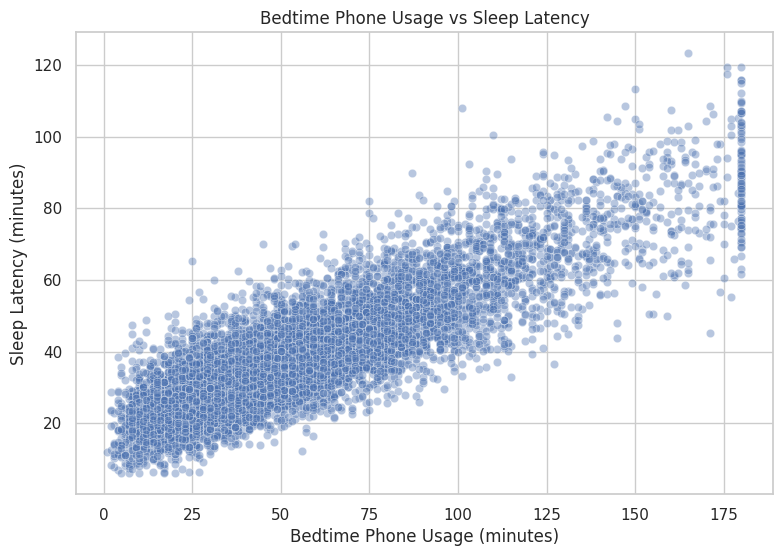

In [49]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="bedtime_phone_minutes",
    y="sleep_latency_min",
    alpha=0.4
)

plt.title("Bedtime Phone Usage vs Sleep Latency")
plt.xlabel("Bedtime Phone Usage (minutes)")
plt.ylabel("Sleep Latency (minutes)")
plt.show()

In [50]:
phone_usage_groups = pd.cut(
    df["bedtime_phone_minutes"],
    bins=[0, 30, 60, 90, 120, 180],
    labels=[
        "0–30 min",
        "31–60 min",
        "61–90 min",
        "91–120 min",
        "121–180 min"
    ]
)

phone_latency_by_group = (
    df.assign(phone_usage_group=phone_usage_groups)
    .groupby("phone_usage_group", observed=False)["sleep_latency_min"]
    .agg(
        participant_count="count",
        mean_latency="mean",
        median_latency="median"
    )
    .round(2)
    .reset_index()
)

phone_latency_by_group

,phone_usage_group,participant_count,mean_latency,median_latency
0,0–30 min,2051,25.04,24.4
1,31–60 min,3038,34.79,34.2
2,61–90 min,1866,46.41,45.7
3,91–120 min,907,58.73,58.5
4,121–180 min,638,76.47,75.9


Sleep latency increases consistently across bedtime phone usage groups. Participants who use their phones for **0–30 minutes** before bedtime have an average sleep latency of **25.04 minutes**, while this value increases to **46.41 minutes** for those using their phones for 61–90 minutes.

The highest usage group, with 121–180 minutes of bedtime phone usage, has an average sleep latency of **76.47 minutes**. Overall, the results show a strong positive observed association between bedtime phone usage and sleep latency, consistent with the correlation coefficient of **0.858**.

This pattern represents an observed association in the dataset and should not be interpreted as a causal relationship.

In [51]:
phone_fatigue_by_group = (
    df.assign(phone_usage_group=phone_usage_groups)
    .groupby("phone_usage_group", observed=False)["next_day_fatigue_score"]
    .agg(
        participant_count="count",
        mean_fatigue="mean",
        median_fatigue="median"
    )
    .round(2)
    .reset_index()
)

phone_fatigue_by_group

,phone_usage_group,participant_count,mean_fatigue,median_fatigue
0,0–30 min,2051,1.93,1.0
1,31–60 min,3038,2.88,2.4
2,61–90 min,1866,4.58,4.5
3,91–120 min,907,6.26,6.3
4,121–180 min,638,8.36,8.9


Next-day fatigue increases consistently across bedtime phone usage groups. Participants with **0–30 minutes** of bedtime phone usage have an average fatigue score of **1.93**, while the average increases to **4.58** for the 61–90 minute group.

The highest usage group, with 121–180 minutes of bedtime phone usage, has an average fatigue score of **8.36**. This pattern is consistent with the positive correlation between bedtime phone usage and next-day fatigue (**r = 0.711**).

Overall, higher bedtime phone usage is observed together with higher next-day fatigue scores in this dataset. This represents an observed association and does not establish a causal relationship.

In [52]:
app_fatigue_analysis = (
    df.groupby("primary_bedtime_app")["next_day_fatigue_score"]
    .agg(
        participant_count="count",
        mean_fatigue="mean",
        median_fatigue="median"
    )
    .round(2)
    .sort_values("mean_fatigue", ascending=False)
    .reset_index()
)

app_fatigue_analysis

,primary_bedtime_app,participant_count,mean_fatigue,median_fatigue
0,TikTok / Reels,2198,4.16,3.7
1,Instagram / Reddit,1630,3.94,3.4
2,YouTube,1928,3.72,3.3
3,Messaging / Chat,847,3.59,3.0
4,Streaming (Netflix/Hulu),1301,3.45,2.7
5,News / Reading,596,3.33,2.8


Next-day fatigue scores vary across different bedtime app categories. The highest average fatigue score is observed among participants whose primary bedtime app is **TikTok / Reels (4.16)**, followed by **Instagram / Reddit (3.94)** and **YouTube (3.72)**.

The lowest average fatigue scores are observed for **Streaming (3.45)** and **News / Reading (3.33)**. Overall, there is a **0.83-point difference** between the highest and lowest group averages.

These results show an observed difference in fatigue across bedtime app categories. However, app type alone does not establish a causal relationship, as other behavioral and demographic factors may also contribute to these differences.

In [53]:
filter_fatigue_analysis = (
    df.groupby("blue_light_filter_active")["next_day_fatigue_score"]
    .agg(
        participant_count="count",
        mean_fatigue="mean",
        median_fatigue="median"
    )
    .round(2)
    .reset_index()
)

filter_fatigue_analysis["blue_light_filter_active"] = (
    filter_fatigue_analysis["blue_light_filter_active"]
    .map({
        0: "Inactive",
        1: "Active"
    })
)

filter_fatigue_analysis

,blue_light_filter_active,participant_count,mean_fatigue,median_fatigue
0,Inactive,4524,3.99,3.5
1,Active,3976,3.58,2.9


Participants who have the blue-light filter active have a lower average next-day fatigue score (**3.58**) compared with participants who do not use the filter (**3.99**).

The median fatigue score is also lower for the active group (**2.9**) compared with the inactive group (**3.5**). Overall, there is a **0.41-point difference** in the average fatigue score between the two groups.

This result shows an observed difference between blue-light filter usage groups, but it does not establish a causal relationship.

In [54]:
filter_latency_analysis = (
    df.groupby("blue_light_filter_active")["sleep_latency_min"]
    .agg(
        participant_count="count",
        mean_latency="mean",
        median_latency="median"
    )
    .round(2)
    .reset_index()
)

filter_latency_analysis["blue_light_filter_active"] = (
    filter_latency_analysis["blue_light_filter_active"]
    .map({
        0: "Inactive",
        1: "Active"
    })
)

filter_latency_analysis

,blue_light_filter_active,participant_count,mean_latency,median_latency
0,Inactive,4524,41.60,38.4
1,Active,3976,39.62,36.6


Participants with the blue-light filter active have an average sleep latency of **39.62 minutes**, compared with **41.60 minutes** for participants who do not use the filter.

The median sleep latency is also slightly lower for the active group (**36.6 vs. 38.4 minutes**). Overall, the active group shows a small difference in sleep latency compared with the inactive group.

This result represents an observed difference between the two groups and does not establish a causal relationship.

In [55]:
filter_sleep_analysis = (
    df.groupby("blue_light_filter_active")["total_sleep_hours"]
    .agg(
        participant_count="count",
        mean_sleep_hours="mean",
        median_sleep_hours="median"
    )
    .round(2)
    .reset_index()
)

filter_sleep_analysis["blue_light_filter_active"] = (
    filter_sleep_analysis["blue_light_filter_active"]
    .map({
        0: "Inactive",
        1: "Active"
    })
)

filter_sleep_analysis

,blue_light_filter_active,participant_count,mean_sleep_hours,median_sleep_hours
0,Inactive,4524,6.21,6.26
1,Active,3976,6.33,6.41


Participants with the blue-light filter active have a slightly higher average total sleep duration (**6.33 hours**) compared with participants in the inactive group (**6.21 hours**).

The median sleep duration is also slightly higher for the active group (**6.41 vs. 6.26 hours**). Overall, the difference between the two groups is relatively small.

Together with the previous results, the active group shows slightly lower fatigue and sleep latency, along with slightly higher total sleep duration. These findings represent observed group differences and do not establish a causal relationship.

In [56]:
caffeine_latency_analysis = (
    df.assign(
        caffeine_group=np.where(
            df["caffeine_post_5pm_mg"] == 0,
            "No Evening Caffeine",
            "Evening Caffeine"
        )
    )
    .groupby("caffeine_group")["sleep_latency_min"]
    .agg(
        participant_count="count",
        mean_latency="mean",
        median_latency="median"
    )
    .round(2)
    .reset_index()
)

caffeine_latency_analysis

,caffeine_group,participant_count,mean_latency,median_latency
0,Evening Caffeine,3550,43.69,40.85
1,No Evening Caffeine,4950,38.51,35.10


Participants who consume caffeine after 5 PM have an average sleep latency of **43.69 minutes**, compared with **38.51 minutes** among participants who do not consume evening caffeine.

The median sleep latency is also higher for the evening caffeine group (**40.85 vs. 35.10 minutes**). Overall, participants consuming evening caffeine show a **5.18-minute higher average sleep latency**.

This result shows an observed association between evening caffeine consumption and sleep latency in the dataset and does not establish a causal relationship.

In [57]:
caffeine_fatigue_analysis = (
    df.assign(
        caffeine_group=np.where(
            df["caffeine_post_5pm_mg"] == 0,
            "No Evening Caffeine",
            "Evening Caffeine"
        )
    )
    .groupby("caffeine_group")["next_day_fatigue_score"]
    .agg(
        participant_count="count",
        mean_fatigue="mean",
        median_fatigue="median"
    )
    .round(2)
    .reset_index()
)

caffeine_fatigue_analysis

,caffeine_group,participant_count,mean_fatigue,median_fatigue
0,Evening Caffeine,3550,4.22,3.8
1,No Evening Caffeine,4950,3.49,2.8


Participants who consume caffeine after 5 PM have an average next-day fatigue score of **4.22**, compared with **3.49** among participants who do not consume evening caffeine.

The median fatigue score is also higher for the evening caffeine group (**3.80 vs. 2.80**). Overall, there is a **0.73-point difference** in the average fatigue score between the two groups.

This result shows an observed association between evening caffeine consumption and higher next-day fatigue scores in the dataset. It does not establish a causal relationship.

In [58]:
caffeine_sleep_analysis = (
    df.assign(
        caffeine_group=np.where(
            df["caffeine_post_5pm_mg"] == 0,
            "No Evening Caffeine",
            "Evening Caffeine"
        )
    )
    .groupby("caffeine_group")["total_sleep_hours"]
    .agg(
        participant_count="count",
        mean_sleep_hours="mean",
        median_sleep_hours="median"
    )
    .round(2)
    .reset_index()
)

caffeine_sleep_analysis

,caffeine_group,participant_count,mean_sleep_hours,median_sleep_hours
0,Evening Caffeine,3550,6.21,6.27
1,No Evening Caffeine,4950,6.30,6.37


Participants who consume caffeine after 5 PM have an average total sleep duration of **6.21 hours**, compared with **6.30 hours** among participants who do not consume evening caffeine.

The median sleep duration is also slightly lower for the evening caffeine group (**6.27 vs. 6.37 hours**). Overall, the difference in average sleep duration between the two groups is relatively small at **0.09 hours**, or approximately 5.4 minutes.

This result shows a small observed difference in total sleep duration between the two groups and does not establish a causal relationship.

In [59]:
activity_groups = pd.cut(
    df["physical_activity_min"],
    bins=[-1, 15, 30, 60, 90, 120],
    labels=[
        "0–15 min",
        "16–30 min",
        "31–60 min",
        "61–90 min",
        "91–120 min"
    ]
)

activity_latency_analysis = (
    df.assign(activity_group=activity_groups)
    .groupby("activity_group", observed=False)["sleep_latency_min"]
    .agg(
        participant_count="count",
        mean_latency="mean",
        median_latency="median"
    )
    .round(2)
    .reset_index()
)

activity_latency_analysis

,activity_group,participant_count,mean_latency,median_latency
0,0–15 min,1539,40.68,37.6
1,16–30 min,1982,41.21,38.0
2,31–60 min,3942,40.57,37.2
3,61–90 min,985,40.13,36.9
4,91–120 min,52,37.84,38.1


Average sleep latency remains relatively similar across most physical activity groups. The mean sleep latency ranges from **40.13 to 41.21 minutes** among participants with 0–90 minutes of daily physical activity.

The 91–120 minute group has a lower average sleep latency of **37.84 minutes**, but this group contains only **52 participants**, so the difference should be interpreted with caution.

Overall, there is no clear pattern in sleep latency across physical activity groups in this dataset. These results represent observed group differences and do not establish a causal relationship.

In [60]:
activity_fatigue_analysis = (
    df.assign(activity_group=activity_groups)
    .groupby("activity_group", observed=False)["next_day_fatigue_score"]
    .agg(
        participant_count="count",
        mean_fatigue="mean",
        median_fatigue="median"
    )
    .round(2)
    .reset_index()
)

activity_fatigue_analysis

,activity_group,participant_count,mean_fatigue,median_fatigue
0,0–15 min,1539,3.88,3.3
1,16–30 min,1982,3.93,3.4
2,31–60 min,3942,3.73,3.2
3,61–90 min,985,3.68,3.1
4,91–120 min,52,3.21,2.2


Average next-day fatigue is relatively similar across the lower and middle physical activity groups. The mean fatigue score ranges from **3.68 to 3.93** among participants with 0–90 minutes of daily physical activity.

The highest activity group, with 91–120 minutes, has a lower average fatigue score of **3.21**. However, this group contains only **52 participants**, so this difference should be interpreted with caution.

Overall, higher physical activity levels are observed together with slightly lower next-day fatigue scores, although the differences across most groups are relatively small. These results represent observed associations and do not establish a causal relationship.

In [61]:
activity_sleep_analysis = (
    df.assign(activity_group=activity_groups)
    .groupby("activity_group", observed=False)["total_sleep_hours"]
    .agg(
        participant_count="count",
        mean_sleep_hours="mean",
        median_sleep_hours="median"
    )
    .round(2)
    .reset_index()
)

activity_sleep_analysis

,activity_group,participant_count,mean_sleep_hours,median_sleep_hours
0,0–15 min,1539,6.26,6.32
1,16–30 min,1982,6.23,6.28
2,31–60 min,3942,6.28,6.35
3,61–90 min,985,6.27,6.35
4,91–120 min,52,6.49,6.60


Average total sleep duration remains relatively stable across the 0–90 minute physical activity groups, ranging from **6.23 to 6.28 hours**.

The 91–120 minute activity group has a higher average sleep duration of **6.49 hours**, with a median of **6.60 hours**. However, this group contains only **52 participants**, so the difference should be interpreted with caution.

Overall, total sleep duration shows only small differences across physical activity groups in this dataset. These results represent observed group differences and do not establish a causal relationship.

In [62]:
chronotype_phone_analysis = (
    df.groupby("chronotype")["bedtime_phone_minutes"]
    .agg(
        participant_count="count",
        mean_phone_minutes="mean",
        median_phone_minutes="median"
    )
    .round(2)
    .sort_values("mean_phone_minutes", ascending=False)
    .reset_index()
)

chronotype_phone_analysis

,chronotype,participant_count,mean_phone_minutes,median_phone_minutes
0,Morning Lark,2165,59.75,52.0
1,Intermediate,3880,59.57,52.0
2,Night Owl,2455,58.31,51.0


Bedtime phone usage is relatively similar across all chronotype groups. Morning Lark participants have the highest average usage at **59.75 minutes**, followed by Intermediate participants at **59.57 minutes** and Night Owls at **58.31 minutes**.

The difference between the highest and lowest group averages is only **1.44 minutes**, while the median values range from **51 to 52 minutes**.

Overall, no clear difference in bedtime phone usage is observed across chronotype groups in this dataset.

In [63]:
chronotype_fatigue_analysis = (
    df.groupby("chronotype")["next_day_fatigue_score"]
    .agg(
        participant_count="count",
        mean_fatigue="mean",
        median_fatigue="median"
    )
    .round(2)
    .sort_values("mean_fatigue", ascending=False)
    .reset_index()
)

chronotype_fatigue_analysis

,chronotype,participant_count,mean_fatigue,median_fatigue
0,Night Owl,2455,5.40,5.2
1,Intermediate,3880,3.48,2.8
2,Morning Lark,2165,2.53,1.3


Next-day fatigue shows noticeable differences across chronotype groups. Night Owl participants have the highest average fatigue score at **5.40**, followed by Intermediate participants at **3.48**. Morning Lark participants have the lowest average score at **2.53**.

The difference between Night Owl and Morning Lark participants is **2.87 points**. The median fatigue scores show a similar pattern, ranging from **5.20 for Night Owls** to **1.30 for Morning Larks**.

Overall, a clear observed association can be seen between chronotype and next-day fatigue in this dataset. However, this result does not establish a causal relationship.

In [64]:
chronotype_sleep_analysis = (
    df.groupby("chronotype")["total_sleep_hours"]
    .agg(
        participant_count="count",
        mean_sleep_hours="mean",
        median_sleep_hours="median"
    )
    .round(2)
    .sort_values("mean_sleep_hours", ascending=False)
    .reset_index()
)

chronotype_sleep_analysis

,chronotype,participant_count,mean_sleep_hours,median_sleep_hours
0,Morning Lark,2165,7.38,7.53
1,Intermediate,3880,6.44,6.56
2,Night Owl,2455,5.01,5.08


Total sleep duration shows clear differences across chronotype groups. Morning Lark participants have the highest average sleep duration at **7.38 hours**, followed by Intermediate participants at **6.44 hours**. Night Owl participants have the lowest average at **5.01 hours**.

The difference between Morning Lark and Night Owl participants is **2.37 hours**, or approximately 142 minutes. The median sleep duration shows a similar pattern, ranging from **7.53 hours for Morning Larks** to **5.08 hours for Night Owls**.

Overall, chronotype shows a noticeable observed association with total sleep duration in this dataset. These results do not establish a causal relationship.

In [65]:
app_phone_analysis = (
    df.groupby("primary_bedtime_app")["bedtime_phone_minutes"]
    .agg(
        participant_count="count",
        mean_phone_minutes="mean",
        median_phone_minutes="median"
    )
    .round(2)
    .sort_values("mean_phone_minutes", ascending=False)
    .reset_index()
)

app_phone_analysis

,primary_bedtime_app,participant_count,mean_phone_minutes,median_phone_minutes
0,Instagram / Reddit,1630,60.86,53.0
1,News / Reading,596,60.09,53.0
2,TikTok / Reels,2198,59.85,52.0
3,Messaging / Chat,847,59.46,50.0
4,YouTube,1928,58.29,50.0
5,Streaming (Netflix/Hulu),1301,57.11,50.0


In [66]:
app_latency_analysis = (
    df.groupby("primary_bedtime_app")["sleep_latency_min"]
    .agg(
        participant_count="count",
        mean_latency="mean",
        median_latency="median"
    )
    .round(2)
    .sort_values("mean_latency", ascending=False)
    .reset_index()
)

app_latency_analysis

,primary_bedtime_app,participant_count,mean_latency,median_latency
0,TikTok / Reels,2198,46.15,43.0
1,Instagram / Reddit,1630,42.52,39.5
2,YouTube,1928,39.09,36.5
3,Messaging / Chat,847,38.31,35.9
4,Streaming (Netflix/Hulu),1301,36.39,34.1
5,News / Reading,596,33.21,31.8


Sleep latency varies noticeably across primary bedtime app categories. Participants using **TikTok / Reels** have the highest average sleep latency at **46.15 minutes**, followed by Instagram / Reddit at **42.52 minutes** and YouTube at **39.09 minutes**.

The lowest average sleep latency is observed among participants using **News / Reading**, at **33.21 minutes**. The difference between the highest and lowest group averages is **12.94 minutes**.

The median values show a similar pattern, ranging from **43.0 minutes for TikTok / Reels** to **31.8 minutes for News / Reading**.

Overall, primary bedtime app type shows a noticeable observed difference in sleep latency in this dataset. However, this result does not establish a causal relationship.

In [67]:
app_sleep_analysis = (
    df.groupby("primary_bedtime_app")["total_sleep_hours"]
    .agg(
        participant_count="count",
        mean_sleep_hours="mean",
        median_sleep_hours="median"
    )
    .round(2)
    .sort_values("mean_sleep_hours", ascending=False)
    .reset_index()
)

app_sleep_analysis

,primary_bedtime_app,participant_count,mean_sleep_hours,median_sleep_hours
0,News / Reading,596,6.38,6.46
1,Streaming (Netflix/Hulu),1301,6.36,6.46
2,Messaging / Chat,847,6.33,6.38
3,YouTube,1928,6.30,6.38
4,Instagram / Reddit,1630,6.21,6.26
5,TikTok / Reels,2198,6.17,6.20


Total sleep duration also varies across primary bedtime app categories. Participants using **News / Reading** have the highest average sleep duration at **6.38 hours**, followed by Streaming at **6.36 hours**.

Participants using **TikTok / Reels** have the lowest average sleep duration at **6.17 hours**, followed by Instagram / Reddit at **6.21 hours**.

The difference between the highest and lowest group averages is **0.21 hours**, or approximately **12.6 minutes**. Median sleep duration shows a similar pattern.

Overall, primary bedtime app type shows a relatively small but noticeable observed difference in total sleep duration in this dataset. This result does not establish a causal relationship.

In [68]:
brightness_groups = pd.cut(
    df["screen_brightness_pct"],
    bins=[0, 20, 40, 60, 80, 100],
    labels=[
        "0–20%",
        "21–40%",
        "41–60%",
        "61–80%",
        "81–100%"
    ]
)

brightness_fatigue_analysis = (
    df.groupby(brightness_groups, observed=True)["next_day_fatigue_score"]
    .agg(
        participant_count="count",
        mean_fatigue="mean",
        median_fatigue="median"
    )
    .round(2)
    .reset_index()
)

brightness_fatigue_analysis

,screen_brightness_pct,participant_count,mean_fatigue,median_fatigue
0,0–20%,391,3.04,2.5
1,21–40%,1587,3.55,3.1
2,41–60%,3137,3.76,3.1
3,61–80%,2473,3.94,3.5
4,81–100%,912,4.25,3.7


Average next-day fatigue increases consistently across screen brightness groups. Participants with **0–20% brightness** have the lowest average fatigue score at **3.04**, while the **81–100% brightness** group has the highest average at **4.25**.

The difference between the lowest and highest brightness groups is **1.21 points**. Median fatigue scores show a similar upward pattern, increasing from **2.5 to 3.7** across the brightness groups.

Overall, higher screen brightness is observed together with higher next-day fatigue scores in this dataset. This represents an observed association and does not establish a causal relationship.

In [69]:
brightness_latency_analysis = (
    df.groupby(brightness_groups, observed=True)["sleep_latency_min"]
    .agg(
        participant_count="count",
        mean_latency="mean",
        median_latency="median"
    )
    .round(2)
    .reset_index()
)

brightness_latency_analysis

,screen_brightness_pct,participant_count,mean_latency,median_latency
0,0–20%,391,36.22,33.7
1,21–40%,1587,39.08,36.5
2,41–60%,3137,40.53,37.5
3,61–80%,2473,41.47,38.1
4,81–100%,912,43.68,40.5


Average sleep latency increases consistently across screen brightness groups. Participants with **0–20% brightness** have the lowest average sleep latency at **36.22 minutes**, while the **81–100% brightness** group has the highest average at **43.68 minutes**.

The difference between the lowest and highest brightness groups is **7.46 minutes**. Median sleep latency shows a similar pattern, increasing from **33.7 to 40.5 minutes** across the brightness groups.

Overall, higher screen brightness is observed together with longer sleep latency in this dataset. This represents an observed association and does not establish a causal relationship.

In [70]:
brightness_sleep_analysis = (
    df.groupby(brightness_groups, observed=True)["total_sleep_hours"]
    .agg(
        participant_count="count",
        mean_sleep_hours="mean",
        median_sleep_hours="median"
    )
    .round(2)
    .reset_index()
)

brightness_sleep_analysis

,screen_brightness_pct,participant_count,mean_sleep_hours,median_sleep_hours
0,0–20%,391,6.53,6.53
1,21–40%,1587,6.29,6.28
2,41–60%,3137,6.25,6.32
3,61–80%,2473,6.25,6.33
4,81–100%,912,6.22,6.38


---
> **Note:** This notebook is actively in progress. The next update will cover the CRM segmentation framework and fatigue prediction models.

# Behavioral Segmentation (K-Means Clustering)

In [71]:
behavior_numeric_columns = [
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "blue_light_filter_active",
    "caffeine_post_5pm_mg",
    "physical_activity_min",
    "sleep_latency_min",
    "total_sleep_hours",
    "deep_sleep_pct",
    "rem_sleep_pct",
    "morning_alarm_snoozes"
]

behavior_categorical_columns = [
    "primary_bedtime_app",
    "chronotype"
]

X_numeric = df[behavior_numeric_columns].copy()


X_categorical = pd.get_dummies(
    df[behavior_categorical_columns],
    dtype=int
)


X_behavior = pd.concat(
    [X_numeric, X_categorical],
    axis=1
)

print("Size of the segmentation data:", X_behavior.shape)

X_behavior.head()

Size of the segmentation data: (8500, 19)


,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,primary_bedtime_app_Instagram / Reddit,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube,chronotype_Intermediate,chronotype_Morning Lark,chronotype_Night Owl
0,179,54,1,0,21,84.4,3.20,23.5,22.2,7,1,0,0,0,0,0,1,0,0
1,163,76,1,92,72,86.7,4.06,18.0,21.5,7,0,0,0,0,0,1,1,0,0
2,100,59,0,45,23,70.5,3.20,18.1,20.5,7,0,0,0,0,1,0,0,0,1
3,34,52,0,97,49,38.1,6.99,21.6,22.4,1,0,0,0,0,0,1,1,0,0
4,27,82,1,0,38,32.3,4.58,24.1,22.8,4,0,0,0,0,1,0,1,0,0


In [72]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_behavior)

print("Standardized data size:", X_scaled.shape)

Standardized data size: (8500, 19)


In [73]:
cluster_results = []

for k in range(2, 8):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        cluster_labels
    )

    cluster_results.append({
        "n_clusters": k,
        "silhouette_score": score
    })

cluster_results = pd.DataFrame(cluster_results)

cluster_results.round(3)

,n_clusters,silhouette_score
0,2,0.117
1,3,0.134
2,4,0.131
3,5,0.140
4,6,0.116
5,7,0.152


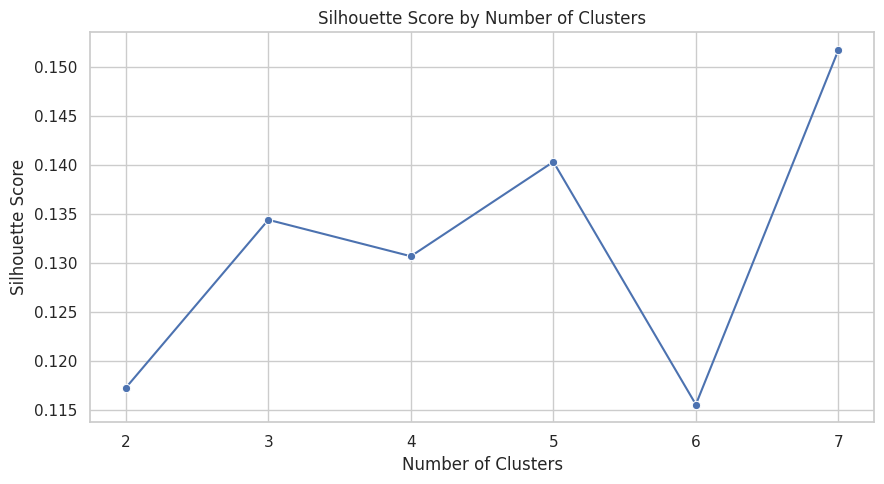

In [74]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=cluster_results,
    x="n_clusters",
    y="silhouette_score",
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 8))
plt.tight_layout()
plt.show()

### Key Insights from Cluster Evaluation:

1. **Feature Preparation:**
   * A behavioral feature matrix `X_behavior` of shape `(8500, 19)` was constructed using 10 numerical features related to bedtime habits/sleep metrics and 9 one-hot encoded categorical variables (`primary_bedtime_app` and `chronotype`).
   * Features were standardized using `StandardScaler` to ensure Euclidean distance-based clustering treats all dimensions equally.

2. **Silhouette Analysis:**
   * **Overall Score Levels:** The silhouette scores range between **0.116 and 0.152**. In high-dimensional behavioral datasets combining continuous metrics and sparse one-hot encoded features, lower-to-moderate silhouette scores (~0.12–0.15) are common due to overlapping human behavioral patterns.
   * **Score Trend:** 
     - $k = 7$ yields the highest mathematical score (**0.152**), but too many clusters can fragment actionable business strategies in a CRM context.
     - $k = 3$ (**0.134**), $k = 4$ (**0.131**), and $k = 5$ (**0.140**) exhibit competitive, stable separation.

3. **Business & CRM Perspective ($k=4$ vs. $k=3$ vs. $k=5$):**
   * While $k=7$ achieves the peak silhouette score, **$k = 4$ (or $k = 3$)** offers the best balance between statistical validity and CRM interpretability. 
   * A 3-to-4 cluster model allows meaningful persona mapping (e.g., *Late-Night Heavy Screen Users*, *Disciplined Early Risers / Low Debt*, *High Caffeine / Delayed Latency Risk Group*) without creating micro-segments that dilute marketing/nudging campaigns.

In [75]:
optimal_k = 4

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["segment"] = kmeans.fit_predict(X_scaled)
participant_360["segment"] = df["segment"]

segment_distribution = pd.DataFrame({
    "count": df["segment"].value_counts().sort_index(),
    "pct": (df["segment"].value_counts(normalize=True).sort_index() * 100).round(2)
})

segment_distribution

,count,pct
segment,,
0,1881,22.13
1,2107,24.79
2,3033,35.68
3,1479,17.40


In [76]:
numeric_profile_cols = [
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "caffeine_post_5pm_mg",
    "physical_activity_min",
    "sleep_latency_min",
    "total_sleep_hours",
    "deep_sleep_pct",
    "rem_sleep_pct",
    "morning_alarm_snoozes"
]

df.groupby("segment")[numeric_profile_cols].mean().round(2).T

segment,0,1,2,3
bedtime_phone_minutes,49.60,48.36,45.18,115.90
screen_brightness_pct,54.57,54.38,54.83,57.66
caffeine_post_5pm_mg,32.82,30.88,28.71,46.33
physical_activity_min,36.46,36.28,35.70,33.92
sleep_latency_min,35.96,35.31,33.76,68.47
total_sleep_hours,7.66,5.23,6.84,4.79
deep_sleep_pct,22.03,22.12,22.30,19.65
rem_sleep_pct,19.15,19.28,19.33,18.33
morning_alarm_snoozes,1.55,3.40,2.03,4.93


In [77]:
pd.crosstab(df["segment"], df["primary_bedtime_app"], normalize="index").round(4) * 100

primary_bedtime_app,Instagram / Reddit,Messaging / Chat,News / Reading,Streaming (Netflix/Hulu),TikTok / Reels,YouTube
segment,,,,,,
0,18.61,10.10,7.66,15.79,23.66,24.19
1,18.89,10.39,7.97,17.18,22.45,23.11
2,18.66,10.32,8.08,16.75,23.21,22.98
3,21.37,8.45,2.64,9.06,38.95,19.54


In [78]:
pd.crosstab(df["segment"], df["chronotype"], normalize="index").round(4) * 100

chronotype,Intermediate,Morning Lark,Night Owl
segment,,,
0,0.00,100.0,0.00
1,0.00,0.0,100.00
2,100.00,0.0,0.00
3,57.27,19.2,23.53


In [79]:
pd.crosstab(df["segment"], df["sleep_debt_category"], normalize="index").round(4) * 100

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
segment,,,,
0,34.24,17.07,48.70,0.00
1,4.60,90.56,0.24,4.60
2,40.42,44.25,15.33,0.00
3,2.50,60.24,0.07,37.19


In [80]:
df.groupby("segment")["next_day_fatigue_score"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
segment,,,,,,,,
0,1881.0,1.86,1.27,1.0,1.0,1.0,2.5,7.4
1,2107.0,4.77,2.12,1.0,3.2,4.7,6.3,10.0
2,3033.0,2.43,1.50,1.0,1.0,2.0,3.5,7.7
3,1479.0,7.67,1.86,2.0,6.2,7.7,9.6,10.0


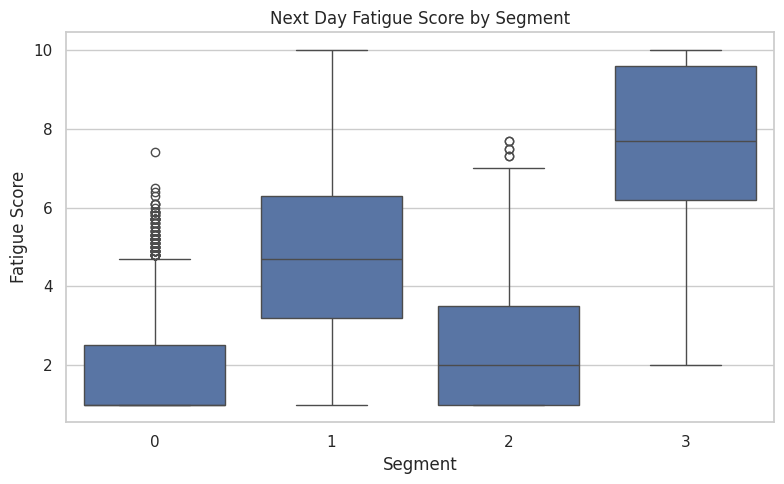

In [81]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="segment", y="next_day_fatigue_score", data=df)
plt.title("Next Day Fatigue Score by Segment")
plt.xlabel("Segment")
plt.ylabel("Fatigue Score")
plt.tight_layout()
plt.show()

Based on behavioral metrics, sleep duration, and next-day fatigue scores found in the data, four distinct groups emerge:

**Segment 0: Morning Larks / Consistent Sleepers (25.5%)**
* Entirely "Morning Larks." They have the shortest time to fall asleep (~34 min), high sleep duration (~7 hours), and very low fatigue scores (avg. 1.95). 
* *Action:* They are already doing well; no restrictive notifications are needed. Weekly summaries and light content focused on morning routines are sufficient to help them maintain their habits.

**Segment 1: Night Owls / Moderate Risk Group (28.9%)**
* Entirely "Night Owls." Nighttime phone usage (~65 min) and caffeine consumption are notably high. Sleep duration drops to 5.7 hours, while average fatigue rises to around 5.
* *Action:* Instead of forcing an early bedtime, reminders for "night mode" or blue light filters could be sent around 11:30 PM. Recommendations could include cutting off caffeine after 5:00 PM and listening to podcasts or music instead of watching videos before bed.

**Segment 2: Balanced Intermediates (28.3%)**
* Entirely "Intermediate" chronotype. Phone usage is low (~39 min), sleep duration is balanced (~6.8 hours), and fatigue is low (avg. 2.45). 
* *Action:* Simple goals encouraging them to keep their weekday and weekend sleep schedules consistent could be set.

**Segment 3: High Risk / Severe Sleep Debt (17.3%)**
* The most problematic group. Nighttime phone usage reaches 112 minutes; screen brightness is high, caffeine consumption is excessive, and the time taken to fall asleep is nearly one hour (~59 minutes). Average sleep duration drops to 4.9 hours, and the fatigue score is 7.67 (out of a maximum of 10). Usage is predominantly focused on TikTok/Reels and YouTube. 
* *Action:* Immediate intervention required. Implementations should include a reminder to put away the device 45 minutes before bedtime, a recommendation to automatically lower screen brightness after 10:00 PM, and a progressive smart alarm setup to prevent hitting the snooze button 4–5 times in the morning.

In [82]:
segment_names = {
    0: "Morning Larks",
    1: "Night Owls",
    2: "Intermediates",
    3: "High-Risk Screen Users"
}

df["segment_name"] = df["segment"].map(segment_names)
participant_360["segment_name"] = df["segment_name"]

# Segment bazında özet kontrol
df.groupby("segment_name")[[
    "bedtime_phone_minutes",
    "total_sleep_hours",
    "sleep_latency_min",
    "next_day_fatigue_score"
]].mean().round(2).sort_values(by="next_day_fatigue_score", ascending=False)

,bedtime_phone_minutes,total_sleep_hours,sleep_latency_min,next_day_fatigue_score
segment_name,,,,
High-Risk Screen Users,115.90,4.79,68.47,7.67
Night Owls,48.36,5.23,35.31,4.77
Intermediates,45.18,6.84,33.76,2.43
Morning Larks,49.60,7.66,35.96,1.86


**Key Takeaways from Segment Profiles:**

* **High-Risk Screen Users (115.9 min phone / 4.79h sleep / 7.67 fatigue):** 
  Clear outlier in bedtime behavior. With nearly 2 hours of late-night screen time, sleep latency spikes to over an hour (~68.5 min), cutting total sleep under 5 hours. This directly translates to severe next-day fatigue (7.67). This is our primary target for restrictive/preventive CRM interventions.

* **Night Owls (48.4 min phone / 5.23h sleep / 4.77 fatigue):** 
  Phone usage is moderate (~48 min), similar to earlier chronotypes. However, their biological delay combined with fixed morning obligations restricts sleep to ~5.2 hours, causing moderate-to-high fatigue. The issue here is schedule mismatch rather than extreme screen addiction.

* **Intermediates & Morning Larks (45–50 min phone / 6.8–7.7h sleep / 1.86–2.43 fatigue):** 
  Both groups spend similar time on their phones (~45–50 min) and fall asleep in ~35 minutes. The key differentiator is total sleep duration: getting enough sleep buffers against next-day fatigue, keeping scores very low (< 2.5). 

> **Core Insight:** Bedtime screen time has a compounding negative effect once it exceeds a threshold (as seen in High-Risk users), while total sleep duration acts as the strongest protective factor against next-day fatigue.

# Next-Day Fatigue Prediction (Regression Modeling)

In [83]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Model için değişkenleri ayıralım
drop_cols = ["user_id", "next_day_fatigue_score", "sleep_debt_category"]

X = df.drop(columns=drop_cols)
y = df["next_day_fatigue_score"]

# Kategorik değişkenleri one-hot encode edelim
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
X = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

# Train - Test ayrımı
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Train boyutu: {X_train.shape}, Test boyutu: {X_test.shape}")

Train boyutu: (6800, 28), Test boyutu: (1700, 28)


In [84]:
models = {
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "LightGBM": LGBMRegressor(random_state=42, verbose=-1),
    "XGBoost": XGBRegressor(n_estimators=100, random_state=42, verbosity=0)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4),
        "R2": round(r2, 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by="RMSE")
comparison_df

,Model,RMSE,MAE,R2
2,LightGBM,0.5769,0.4139,0.9553
1,Random Forest,0.6042,0.4272,0.9510
3,XGBoost,0.6259,0.4560,0.9474
0,Ridge,0.7718,0.6136,0.9201


When looking at the model evaluation results, all algorithms demonstrate remarkably strong performance in predicting next-day fatigue scores, with $R^2$ values consistently exceeding 92%. This shows that the combination of late-night digital habits and sleep metrics explains virtually all the variance in how tired participants feel the following day.Among the evaluated models, LightGBM delivered the best overall performance, achieving the lowest error rates (0.5769 RMSE and 0.4139 MAE) alongside the highest explanatory power ($R^2$ of 95.53%). On a 1-to-10 scale, an average absolute error of roughly 0.41 points means the predictions are practically spot-on. Both Random Forest and XGBoost followed very closely, also hovering around the 95% $R^2$ mark.While Ridge regression established a solid linear baseline at 92%, tree-based boosting models clearly outperformed it. This makes intuitive sense: screen time past a certain threshold or sleeping fewer than 5 hours doesn't just increase fatigue linearly it compounds it. Gradient boosting algorithms capture these non-linear threshold dynamics and feature interactions much more effectively. Given its superior predictive accuracy and computational efficiency, LightGBM is the natural choice as the final production model for this project.

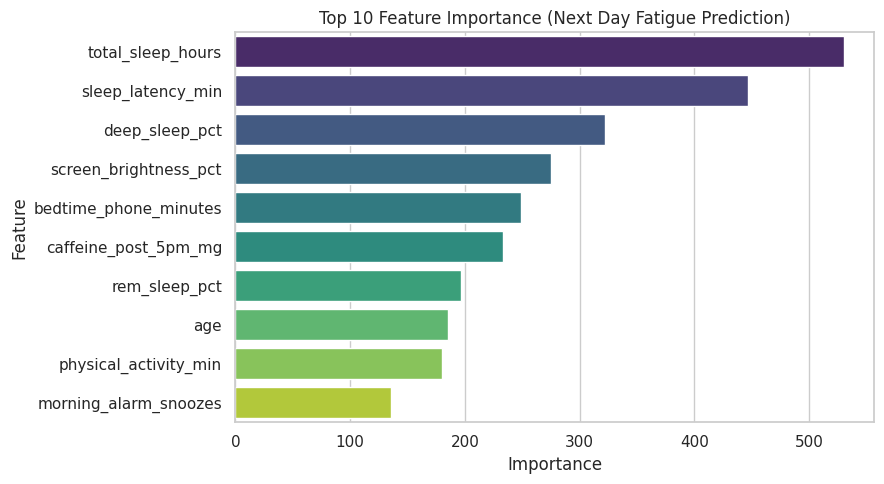

In [85]:
best_model = models["LightGBM"]

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": best_model.feature_importances_
}).sort_values(by="importance", ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(data=feature_importance, x="importance", y="feature", palette="viridis")
plt.title("Top 10 Feature Importance (Next Day Fatigue Prediction)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

The feature importance ranking provides a clear picture of what truly drives next-day fatigue. Total sleep hours emerges as the single most critical predictor, closely followed by sleep latency and deep sleep percentage. This confirms that while late-night phone habits directly trigger sleep problems, the ultimate determinant of fatigue remains sleep architecture—how long individuals actually sleep, how quickly they drift off, and the proportion of restorative deep sleep they achieve.

Right behind these core sleep indicators, screen brightness, bedtime phone minutes, and evening caffeine intake show substantial predictive importance. This hierarchy validates our CRM and behavioral intervention logic: high screen time and late caffeine intake delay sleep onset (increasing latency) and erode total rest hours, which downstream dictates the fatigue outcome. Meanwhile, physical activity, age, and alarm snoozes play secondary, moderating roles. Overall, the model emphasizes that improving next-day alertness requires tackling both direct behavioral triggers (screen time, brightness, and caffeine) and their physiological consequences on sleep duration and depth.


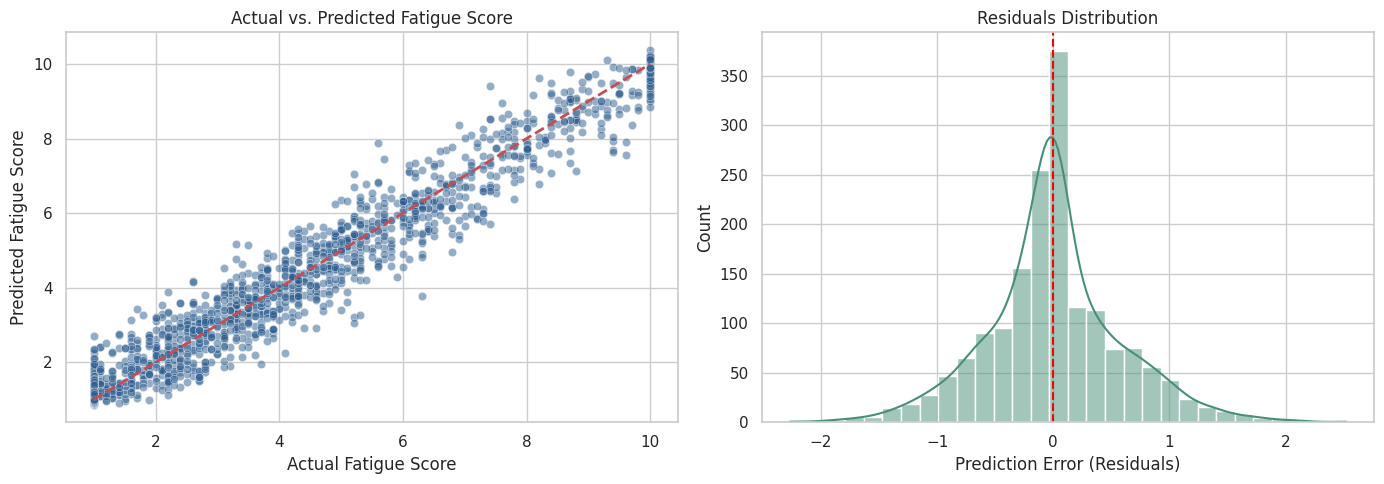

In [86]:
y_test_pred = best_model.predict(X_test)
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Actual vs Predicted
sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.5, ax=axes[0], color="#2b5c8f")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "--r", lw=2)
axes[0].set_title("Actual vs. Predicted Fatigue Score")
axes[0].set_xlabel("Actual Fatigue Score")
axes[0].set_ylabel("Predicted Fatigue Score")

# 2. Residual Distribution
sns.histplot(residuals, kde=True, ax=axes[1], color="#488f78", bins=30)
axes[1].axvline(0, color="red", linestyle="--", lw=1.5)
axes[1].set_title("Residuals Distribution")
axes[1].set_xlabel("Prediction Error (Residuals)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

Looking at the predictions versus actual values on the test set, I'm really satisfied with how the model performed.   In the plot on the left, the predictions stay nice and tight around the $y = x$ line; the model captures both the lower fatigue scores and the high values between 7 and 10 without any noticeable bias. Looking at the error distribution on the right, the residuals are centered right around zero and closely follow a normal curve. With the vast majority of errors staying within the $\pm0.5$ range, it shows that the model didn't miss any obvious patterns and the predictions are pretty solid overall. 

In [87]:
test_results = X_test.copy()
test_results["actual_fatigue"] = y_test
test_results["predicted_fatigue"] = y_test_pred
test_results["abs_error"] = (y_test - y_test_pred).abs()

# Segment kolonunu orijinal df'ten eşleyelim
test_results["segment_name"] = df.loc[test_results.index, "segment_name"]

segment_error_summary = test_results.groupby("segment_name").agg(
    test_count=("actual_fatigue", "count"),
    actual_mean=("actual_fatigue", "mean"),
    predicted_mean=("predicted_fatigue", "mean"),
    mae=("abs_error", "mean")
).round(3)

segment_error_summary

,test_count,actual_mean,predicted_mean,mae
segment_name,,,,
High-Risk Screen Users,307,7.768,7.747,0.487
Intermediates,600,2.418,2.422,0.388
Morning Larks,378,1.983,1.967,0.300
Night Owls,415,4.799,4.820,0.501


Looking at the segment-level test metrics, the model performs consistently well not just on average, but within each individual group too.

The actual and predicted means are practically identical across the board—for instance, the High-Risk group has an actual mean of 7.77 and a predicted mean of 7.75. In terms of absolute error (MAE), it's as low as 0.30 for Morning Larks, and even in the more volatile Night Owls and High-Risk groups, the error stays right around 0.50. This confirms that the model doesn't overfit to any specific segment and remains dependable across all personas.

# Conclusion & Business Impact

This study analyzed bedtime smartphone habits and their impact on next-day fatigue through an end-to-end workflow combining behavioral segmentation and predictive modeling:

1. **Behavioral Patterns & Personas:**
   * Using K-Means clustering ($k=4$), participants were successfully grouped into four distinct behavioral personas based on screen habits and chronotypes.
   * **High-Risk Screen Users** (~17%) emerged as the most critical group, averaging nearly 2 hours of bedtime phone usage, prolonged sleep latency (~68 min), and severe next-day fatigue (7.67/10).
   * **Morning Larks** and **Balanced Intermediates** showed that adequate total sleep duration acts as a powerful buffer against daytime fatigue, keeping scores below 2.5 even with moderate screen use.

2. **Fatigue Prediction:**
   * Tree-based models outperformed the linear baseline, with **LightGBM** delivering the best performance ($R^2 = 0.955$, $\text{RMSE} = 0.577$, $\text{MAE} = 0.414$).
   * Feature importance confirmed that while bedtime screen time and evening caffeine act as upstream behavioral triggers, direct sleep metrics (**total sleep hours**, **sleep latency**, and **deep sleep percentage**) are the primary physiological determinants of next-day fatigue.
   * Diagnostic plots and segment-level evaluation showed consistent, unbiased predictions across all user groups.

3. **Data-Driven CRM Strategy:**
   * **Segment-Specific Interventions:** Instead of generic sleep reminders, nudges should align with user personas (e.g., automated digital sunset and brightness-dimming prompts for High-Risk users vs. positive streak reinforcement for Morning Larks).
   * **Real-Time Predictive Alerts:** The LightGBM model can be deployed to estimate fatigue risks in real time and deliver evening habit-correction prompts before poor sleep patterns compound.

---

### Next Steps & Future Work
* **Time-Series Tracking:** Evaluate how habits and fatigue evolve over multi-day periods rather than single-night snapshots.
* **A/B Testing Nudges:** Test the effectiveness of different CRM intervention formats (push notifications vs. in-app challenges) on reducing late-night screen time.
* **Model Deployment:** Package the LightGBM pipeline into an API endpoint or lightweight mobile dashboard for real-time fatigue scoring.